VetIQ | Veterinary Tick Demand Forecasting

1. Project Overview

This project investigates whether environmental conditions and online search behaviour can improve the forecasting of tick-related veterinary consultation demand in South East Queensland (SEQ), Australia.

The analysis integrates veterinary consultation records with historical weather data from Open-Meteo and Google Trends search-interest data. The primary objective is to forecast tick-related veterinary consultation demand two weeks in advance and evaluate whether external predictors improve forecasting performance compared with historical-demand baselines.

The analytical workflow includes consultation dataset integration, data cleaning, geographical selection of SEQ clinics, tick-related consultation identification, weekly demand aggregation, exploratory data analysis, feature engineering, correlation and lag analysis, forecasting model development, and model evaluation.

Research Objectives

Analyse historical trends and seasonal patterns in tick-related veterinary consultations across SEQ clinics.

Investigate relationships between Open-Meteo weather variables, Google Trends search interest and veterinary tick-related demand.

Develop and compare forecasting models for two-week-ahead demand prediction.

Evaluate whether weather and Google Trends predictors improve forecasting accuracy over historical-demand baselines.

Prepare analytical outputs for an interactive veterinary demand forecasting dashboard.

## 2. Environment Setup and Library Imports

This section initialises the Python environment and defines the project directories used throughout the analysis. The required libraries support data manipulation, numerical computation, visualisation and file management.

In [1]:
# ============================================================
# 2.1 IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

from pathlib import Path

# ============================================================
# 2.2 PROJECT DIRECTORIES
# ============================================================

PROJECT_DIR = Path(
    "/Users/sreelakshmi/Desktop/RMIT_final/project"
)

DATA_DIR = PROJECT_DIR / "Tick Analysis"

# ============================================================
# 2.3 VERIFY PROJECT DIRECTORIES
# ============================================================

print("Project directory:", PROJECT_DIR)
print("Dataset directory:", DATA_DIR)

print("\nDirectory validation:")
print("Project directory exists:", PROJECT_DIR.exists())
print("Dataset directory exists:", DATA_DIR.exists())

Project directory: /Users/sreelakshmi/Desktop/RMIT_final/project
Dataset directory: /Users/sreelakshmi/Desktop/RMIT_final/project/Tick Analysis

Directory validation:
Project directory exists: True
Dataset directory exists: True


## 3. Data Collection and Dataset Loading

The study uses veterinary consultation records provided by VetIQ to investigate tick-related consultation demand across South East Queensland.

Two consultation datasets are used:

- **Consultation.csv:** Structured veterinary consultation records.
- **consultations_freetext.csv:** Additional consultation records containing free-text information.

The datasets are initially inspected to assess their structure, record counts, available attributes and temporal coverage before integration and preprocessing.

Additional environmental and search-interest data from Open-Meteo and Google Trends are incorporated in subsequent stages of the analysis.

### 3.1 Loading the Consultation Datasets

In [2]:
# ============================================================
# 3.1 LOCATE CONSULTATION DATASETS
# ============================================================

consultation_files = sorted(
    PROJECT_DIR.rglob("Consultation.csv")
)

freetext_files = sorted(
    PROJECT_DIR.rglob("consultations_freetext.csv")
)

print("Consultation.csv locations:")
for path in consultation_files:
    print(path)

print("\nconsultations_freetext.csv locations:")
for path in freetext_files:
    print(path)

print("\nNumber of matching files:")
print("Consultation.csv:", len(consultation_files))
print("consultations_freetext.csv:", len(freetext_files))

Consultation.csv locations:
/Users/sreelakshmi/Desktop/RMIT_final/project/Tick Analysis/Consultation.csv

consultations_freetext.csv locations:
/Users/sreelakshmi/Desktop/RMIT_final/project/cleaned/consultations_freetext.csv

Number of matching files:
Consultation.csv: 1
consultations_freetext.csv: 1


In [3]:
# ============================================================
# 3.2 LOAD AND INSPECT CONSULTATION DATASETS
# ============================================================

# Confirm the exact dataset paths
consultation_path = consultation_files[0]
freetext_path = freetext_files[0]

# Load the datasets
consultation_df = pd.read_csv(
    consultation_path,
    low_memory=False
)

freetext_df = pd.read_csv(
    freetext_path,
    low_memory=False
)

# Display dataset dimensions
print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)

print("\nConsultation.csv")
print("Rows:", consultation_df.shape[0])
print("Columns:", consultation_df.shape[1])

print("\nconsultations_freetext.csv")
print("Rows:", freetext_df.shape[0])
print("Columns:", freetext_df.shape[1])

# Display column names
print("\n" + "=" * 60)
print("COLUMN STRUCTURE")
print("=" * 60)

print("\nConsultation.csv columns:")
print(consultation_df.columns.tolist())

print("\nconsultations_freetext.csv columns:")
print(freetext_df.columns.tolist())

# Display sample records
print("\nConsultation.csv sample:")
display(consultation_df.head(3))

print("\nconsultations_freetext.csv sample:")
display(freetext_df.head(3))

DATASET OVERVIEW

Consultation.csv
Rows: 1048575
Columns: 13

consultations_freetext.csv
Rows: 6748676
Columns: 9

COLUMN STRUCTURE

Consultation.csv columns:
['ConsultationKey', 'ClientKey', 'PatientKey', 'ClinicID', 'ConsultingVetUserID', 'ConsultationDate', 'ConsultationDateTime', 'ItemServiceFeeName', 'ItemServiceQty', 'TotalSalePriceAmt', 'TotalTaxAmt', 'ConsultationWeightDecimal', 'ConsultationTemperatureDecimal']

consultations_freetext.csv columns:
['ConsultationKey', 'ClinicPseudonym', 'ConsultationDate', 'ExaminationTextString', 'SummaryString', 'SpecialInstructionString', 'PossibleNameMatch_ClientFirstName', 'PossibleNameMatch_ClientLastName', 'PossibleNameMatch_PatientName']

Consultation.csv sample:


,ConsultationKey,ClientKey,PatientKey,ClinicID,ConsultingVetUserID,ConsultationDate,ConsultationDateTime,ItemServiceFeeName,ItemServiceQty,TotalSalePriceAmt,TotalTaxAmt,ConsultationWeightDecimal,ConsultationTemperatureDecimal
0,A726C982F0D077B2DBDA21FA915EF54B4E6C503BC9BEC1...,8EF77BC3887680F6917A161EB3792678B7EBB0E4416661...,ADC1F5AB2D9E79C2639910D798B2D79711774839FEC019...,8,-1,1/10/2021,NaN,Standard Fee,1.0,69.0,6.2727,NaN,NaN
1,37BDEB8EE25F1103F14F312F351F32BE25CBB908F2E9F9...,8EF77BC3887680F6917A161EB3792678B7EBB0E4416661...,ADC1F5AB2D9E79C2639910D798B2D79711774839FEC019...,8,-1,1/10/2021,NaN,Standard Fee,1.0,23.9,2.1727,NaN,NaN
2,9914B7E657C41B48039E8F87F2453BAF4E0F6750190834...,8EF77BC3887680F6917A161EB3792678B7EBB0E4416661...,ADC1F5AB2D9E79C2639910D798B2D79711774839FEC019...,8,-1,1/10/2021,NaN,Standard Fee,1.0,14.8,1.3454,NaN,NaN



consultations_freetext.csv sample:


,ConsultationKey,ClinicPseudonym,ConsultationDate,ExaminationTextString,SummaryString,SpecialInstructionString,PossibleNameMatch_ClientFirstName,PossibleNameMatch_ClientLastName,PossibleNameMatch_PatientName
0,9A763DD0D42112D82E510D667E5F4A5F1E6FA1A3F2B42C...,Clinic_01,2023-07-27,Reason: Admit For BGC Fed 1 cup dry food at 6...,NaN,NaN,0,0,0
1,854150406CECBEE128992D93EF0FB60DBE7407E6A98AE1...,Clinic_01,2023-07-27,Reason: Admit For BGC Fed 1 cup dry food at 6...,NaN,NaN,0,0,0
2,AF349A69219EA3A30DC4785DF88BB03F8B8B9607C05C8F...,Clinic_01,2023-07-27,Reason: Admit For BGC Fed 1 cup dry food at 6...,NaN,NaN,0,0,0


### 3.3 Consultation Identifier and Dataset Overlap Validation

The two consultation datasets contain different clinical attributes and clinic identifiers. Before integration, consultation identifiers are examined to identify duplicate records and determine whether consultations overlap across the datasets.

This validation supports accurate consultation-level aggregation and prevents duplicated records from inflating demand estimates.

In [4]:
# ============================================================
# 3.3 CONSULTATION IDENTIFIER VALIDATION
# ============================================================

# Standardise consultation identifiers
consultation_df["ConsultationKey"] = (
    consultation_df["ConsultationKey"]
    .astype("string")
    .str.strip()
)

freetext_df["ConsultationKey"] = (
    freetext_df["ConsultationKey"]
    .astype("string")
    .str.strip()
)

# Extract valid consultation identifiers
structured_keys = consultation_df["ConsultationKey"].dropna()
freetext_keys = freetext_df["ConsultationKey"].dropna()

# Count unique consultation identifiers
structured_unique = structured_keys.nunique()
freetext_unique = freetext_keys.nunique()

# Identify duplicates within each dataset
structured_duplicates = len(structured_keys) - structured_unique
freetext_duplicates = len(freetext_keys) - freetext_unique

# Identify consultations appearing in both datasets
overlapping_keys = len(
    pd.Index(structured_keys.unique()).intersection(
        pd.Index(freetext_keys.unique())
    )
)

# Display validation results
print("=" * 60)
print("CONSULTATION IDENTIFIER VALIDATION")
print("=" * 60)

print("\nStructured consultations:")
print("Total records:", len(consultation_df))
print("Unique consultation keys:", structured_unique)
print("Repeated consultation keys:", structured_duplicates)

print("\nFree-text consultations:")
print("Total records:", len(freetext_df))
print("Unique consultation keys:", freetext_unique)
print("Repeated consultation keys:", freetext_duplicates)

print("\nCross-dataset overlap:")
print("Shared consultation keys:", overlapping_keys)

print(
    "Unique consultations across both datasets:",
    structured_unique + freetext_unique - overlapping_keys
)

CONSULTATION IDENTIFIER VALIDATION

Structured consultations:
Total records: 1048575
Unique consultation keys: 1048575
Repeated consultation keys: 0

Free-text consultations:
Total records: 6748676
Unique consultation keys: 6139791
Repeated consultation keys: 608885

Cross-dataset overlap:
Shared consultation keys: 152256
Unique consultations across both datasets: 7036110


### 3.4 Clinic Identifier Standardisation

The free-text consultation dataset represents clinic identifiers using the format `Clinic_XX`, whereas the structured consultation dataset contains a numeric `ClinicID`.

Following clarification from the industry partner, the `Clinic_` prefix is removed and the remaining numeric value is converted into a standardised clinic identifier.

This enables consistent clinic-level processing across the consultation datasets and supports subsequent geographical filtering for South East Queensland.

In [5]:
# ============================================================
# 3.4 STANDARDISE CLINIC IDENTIFIERS
# ============================================================

# Convert free-text clinic pseudonyms to numeric ClinicID
freetext_df["ClinicID"] = pd.to_numeric(
    freetext_df["ClinicPseudonym"]
    .astype("string")
    .str.strip()
    .str.replace(r"^Clinic_", "", regex=True),
    errors="coerce"
).astype("Int64")

# Standardise ClinicID in structured consultation dataset
consultation_df["ClinicID"] = pd.to_numeric(
    consultation_df["ClinicID"],
    errors="coerce"
).astype("Int64")

# Verify clinic identifiers
print("Structured dataset clinics:",
      consultation_df["ClinicID"].nunique())

print("Free-text dataset clinics:",
      freetext_df["ClinicID"].nunique())

print("Missing free-text ClinicIDs:",
      freetext_df["ClinicID"].isna().sum())

# Display the clinic identifier mapping
display(
    freetext_df[["ClinicPseudonym", "ClinicID"]]
    .drop_duplicates()
    .sort_values("ClinicID")
    .reset_index(drop=True)
)

Structured dataset clinics: 23
Free-text dataset clinics: 58
Missing free-text ClinicIDs: 0


,ClinicPseudonym,ClinicID
0,Clinic_01,1
1,Clinic_02,2
2,Clinic_03,3
3,Clinic_04,4
4,Clinic_05,5
5,Clinic_06,6
6,Clinic_07,7
7,Clinic_08,8
8,Clinic_10,10
9,Clinic_11,11


#### Clinic Identifier Standardisation Results

Clinic identifiers were successfully standardised across both
consultation datasets following the industry partner's guidance.

The structured consultation dataset contained 23 distinct
clinics, while the free-text consultation dataset contained
58 distinct clinics.

All free-text clinic pseudonyms were successfully converted
into numeric ClinicIDs, with no missing identifiers.

The standardised identifiers provide a consistent basis for
integrating consultation records and identifying clinics
located within South East Queensland.

Section 3.5. Clinic Coverage Validation

In [6]:
# ============================================================
# 3.5 CLINIC COVERAGE AND OVERLAP VALIDATION
# ============================================================

structured_clinics = set(
    consultation_df["ClinicID"].dropna().astype(int).unique()
)

freetext_clinics = set(
    freetext_df["ClinicID"].dropna().astype(int).unique()
)

common_clinics = structured_clinics & freetext_clinics
structured_only = structured_clinics - freetext_clinics
freetext_only = freetext_clinics - structured_clinics

print("=" * 60)
print("CLINIC COVERAGE VALIDATION")
print("=" * 60)

print("Structured dataset clinics:", len(structured_clinics))
print("Free-text dataset clinics:", len(freetext_clinics))
print("Clinics appearing in both:", len(common_clinics))
print("Structured-only clinics:", len(structured_only))
print("Free-text-only clinics:", len(freetext_only))
print("Total distinct clinics:", len(structured_clinics | freetext_clinics))

print("\nCommon ClinicIDs:")
print(sorted(common_clinics))

print("\nStructured-only ClinicIDs:")
print(sorted(structured_only))

print("\nFree-text-only ClinicIDs:")
print(sorted(freetext_only))

CLINIC COVERAGE VALIDATION
Structured dataset clinics: 23
Free-text dataset clinics: 58
Clinics appearing in both: 3
Structured-only clinics: 20
Free-text-only clinics: 55
Total distinct clinics: 78

Common ClinicIDs:
[np.int64(8), np.int64(21), np.int64(22)]

Structured-only ClinicIDs:
[np.int64(96), np.int64(99), np.int64(101), np.int64(102), np.int64(104), np.int64(105), np.int64(106), np.int64(107), np.int64(108), np.int64(109), np.int64(112), np.int64(130), np.int64(131), np.int64(136), np.int64(138), np.int64(154), np.int64(176), np.int64(241), np.int64(329), np.int64(338)]

Free-text-only ClinicIDs:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), 

#### Clinic Coverage Validation Results

The structured consultation dataset contained 23 distinct clinics,
while the free-text consultation dataset contained 58 distinct clinics.

Three clinics (ClinicIDs 8, 21 and 22) were represented in both
datasets. The remaining clinics were unique to their respective
sources, resulting in 78 distinct clinic identifiers across the
combined data sources.

These findings indicate that the datasets provide largely
complementary clinic coverage. The integration procedure must
preserve consultations from both sources while accounting for
overlapping consultation identifiers.

Geographical filtering will subsequently be applied to identify
clinics located within South East Queensland.

Section 3.6. Consultation Consistency Validation

In [7]:
# ============================================================
# 3.6 VALIDATE SHARED CONSULTATION RECORDS
# ============================================================

# Extract one record per consultation key from each dataset
structured_check = (
    consultation_df[
        ["ConsultationKey", "ClinicID", "ConsultationDate"]
    ]
    .drop_duplicates(subset=["ConsultationKey"])
    .copy()
)

freetext_check = (
    freetext_df[
        ["ConsultationKey", "ClinicID", "ConsultationDate"]
    ]
    .drop_duplicates(subset=["ConsultationKey"])
    .copy()
)

# Compare consultations appearing in both sources
shared_check = structured_check.merge(
    freetext_check,
    on="ConsultationKey",
    how="inner",
    suffixes=("_structured", "_freetext"),
    validate="one_to_one"
)

# Standardise dates for comparison
for col in [
    "ConsultationDate_structured",
    "ConsultationDate_freetext"
]:
    shared_check[col] = pd.to_datetime(
        shared_check[col],
        dayfirst=(col == "ConsultationDate_structured"),
        errors="coerce"
    )

clinic_match = (
    shared_check["ClinicID_structured"]
    == shared_check["ClinicID_freetext"]
)

date_match = (
    shared_check["ConsultationDate_structured"]
    == shared_check["ConsultationDate_freetext"]
)

print("=" * 60)
print("SHARED CONSULTATION VALIDATION")
print("=" * 60)

print("Shared consultation keys:", len(shared_check))
print("Matching clinic IDs:", clinic_match.sum())
print("Different clinic IDs:", (clinic_match == False).sum())
print("Matching dates:", date_match.sum())
print("Different dates:", (date_match == False).sum())

print("\nSample shared records:")
display(shared_check.head(5))

SHARED CONSULTATION VALIDATION
Shared consultation keys: 152256
Matching clinic IDs: 0
Different clinic IDs: 152256
Matching dates: 136471
Different dates: 15785

Sample shared records:


,ConsultationKey,ClinicID_structured,ConsultationDate_structured,ClinicID_freetext,ConsultationDate_freetext
0,6EEDA8675BD578BC664974AE7F26B99DC3BE08A3A04DF0...,21,2021-10-01,49,2025-12-16
1,D2F0A1998093055617570DA37BDB6FB7B28D46CCE2EC07...,21,2021-10-01,49,2025-12-16
2,DA35D0933046A9F4B52FE8A48A0E2D90341EF6F2919CB4...,21,2021-10-01,49,2025-12-16
3,DFFC10C8CBFF702D8A31D5CECCAC87142001F7344CD2E9...,21,2021-10-01,49,2025-12-16
4,FCA7C5B24CF2EE8B0E404FFDB0748F80E1061C0A6F235C...,21,2021-10-01,49,2025-12-16


Section 3.7: Load and Validate the Combined Historical Dataset

### 3.7 Historical Consultation Dataset Integration

The historical consultation dataset was prepared by combining records from two VetIQ data sources: `Consultation.csv` and `consultations_freetext.csv`.

Clinic identifiers were standardised by removing the `Clinic_` prefix from the free-text dataset's clinic pseudonyms, following guidance from the industry partner. The datasets were brought into a common structure containing consultation identifiers, clinic identifiers, consultation dates, service descriptions, clinical notes and data-source labels.

The resulting dataset, `consultations_5year_combined.csv`, was used as the primary historical consultation data source for subsequent preprocessing and analysis.

Before forecasting, the combined dataset was validated for temporal coverage, clinic representation and consultation identifier consistency. Particular attention was given to overlapping consultation identifiers across the two sources to avoid inappropriate assumptions about duplicate clinical events.

In [8]:
# ============================================================
# 3.7 LOAD AND VALIDATE COMBINED HISTORICAL DATASET
# ============================================================

COMBINED_FILE = PROJECT_DIR / "consultations_5year_combined.csv"

combined_df = pd.read_csv(
    COMBINED_FILE,
    low_memory=False
)

# Standardise essential fields
combined_df["ConsultationDate"] = pd.to_datetime(
    combined_df["ConsultationDate"],
    errors="coerce"
)

combined_df["ClinicID"] = pd.to_numeric(
    combined_df["ClinicID"],
    errors="coerce"
).astype("Int64")

print("=" * 60)
print("COMBINED HISTORICAL DATASET")
print("=" * 60)

print("Total records:", len(combined_df))
print("Unique consultation keys:",
      combined_df["ConsultationKey"].nunique())
print("Unique clinics:",
      combined_df["ClinicID"].nunique())

print("\nDate range:")
print("Start:", combined_df["ConsultationDate"].min())
print("End:", combined_df["ConsultationDate"].max())

print("\nRecords by source:")
print(combined_df["DataSource"].value_counts(dropna=False))

print("\nRecords by year:")
print(
    combined_df["ConsultationDate"]
    .dt.year
    .value_counts()
    .sort_index()
)

print("\nMissing essential values:")
print(
    combined_df[
        ["ConsultationKey", "ClinicID", "ConsultationDate"]
    ].isna().sum()
)

COMBINED HISTORICAL DATASET
Total records: 7641896
Unique consultation keys: 7036110
Unique clinics: 78

Date range:
Start: 2021-10-01 00:00:00
End: 2026-08-26 00:00:00

Records by source:
DataSource
consultations_freetext.csv    6593321
Consultation.csv              1048575
Name: count, dtype: int64

Records by year:
ConsultationDate
2021     126446
2022     499206
2023    1087803
2024    1962988
2025    2108665
2026    1856788
Name: count, dtype: int64

Missing essential values:
ConsultationKey     0
ClinicID            0
ConsultationDate    0
dtype: int64


## 4. Data Preprocessing and Cleaning

The combined historical consultation dataset was subjected to
preprocessing to ensure consistency and reliability before
geographical filtering and forecasting analysis.

Preprocessing included validation of consultation dates,
clinic identifiers, missing values, repeated consultation
records, and the availability of clinical text fields.

The objective was to establish a consistent analytical
dataset while preserving the historical consultation
coverage required for tick-related demand forecasting.

### 4.1 Data Quality Assessment

In [9]:
# ============================================================
# 4.1 DATA QUALITY ASSESSMENT
# ============================================================

print("=" * 60)
print("COMBINED DATASET QUALITY ASSESSMENT")
print("=" * 60)

print("\nDataset dimensions:")
print(combined_df.shape)

print("\nColumn data types:")
print(combined_df.dtypes)

print("\nMissing values:")
display(
    combined_df.isna().sum().to_frame("Missing Values")
)

print("\nRepeated consultation keys:")
print(combined_df["ConsultationKey"].duplicated().sum())

print("\nExact duplicate rows:")
print(combined_df.duplicated().sum())

print("\nUnique clinics:")
print(combined_df["ClinicID"].nunique())

print("\nDate range:")
print(combined_df["ConsultationDate"].min())
print(combined_df["ConsultationDate"].max())

COMBINED DATASET QUALITY ASSESSMENT

Dataset dimensions:
(7641896, 9)

Column data types:
ConsultationKey                     object
ClinicID                             Int64
ClinicPseudonym                     object
ConsultationDate            datetime64[ns]
ItemServiceFeeName                  object
ExaminationTextString               object
SummaryString                       object
SpecialInstructionString            object
DataSource                          object
dtype: object

Missing values:


,Missing Values
ConsultationKey,0
ClinicID,0
ClinicPseudonym,0
ConsultationDate,0
ItemServiceFeeName,6875253
ExaminationTextString,4728700
SummaryString,6966802
SpecialInstructionString,7620622
DataSource,0



Repeated consultation keys:
605786

Exact duplicate rows:
0

Unique clinics:
78

Date range:
2021-10-01 00:00:00
2026-08-26 00:00:00


### 4.2 Clinic Identifier Consistency

The combined consultation dataset contains both ClinicID and
ClinicPseudonym. The clinic pseudonym was standardised by
removing the "Clinic_" prefix and converting the remaining
value into a numeric identifier.

The consistency of both identifiers was assessed before
removing the redundant pseudonym column from the analytical
dataset. The original combined dataset was preserved.

In [10]:

# ============================================================
# 4.2 CLINIC IDENTIFIER CONSISTENCY
# ============================================================

# Extract numeric clinic ID from pseudonym
extracted_clinic_id = pd.to_numeric(
    combined_df["ClinicPseudonym"]
    .astype("string")
    .str.strip()
    .str.replace(r"^Clinic_", "", regex=True),
    errors="coerce"
).astype("Int64")

# Compare the identifiers
mismatch = (
    extracted_clinic_id.isna()
    | combined_df["ClinicID"].isna()
    | extracted_clinic_id.ne(combined_df["ClinicID"]).fillna(True)
)

print("=" * 60)
print("CLINIC IDENTIFIER CONSISTENCY")
print("=" * 60)

print("Total records:", len(combined_df))
print("Matching identifiers:", (~mismatch).sum())
print("Mismatched identifiers:", mismatch.sum())

# Keep both identifiers if mapping is consistent
if not mismatch.any():
    cleaned_df = combined_df.copy()

    print("\nClinicPseudonym retained in analytical dataset.")
    print("Cleaned dataset shape:", cleaned_df.shape)
    print("\nRemaining columns:")
    print(cleaned_df.columns.tolist())
else:
    print("\nIdentifier mismatches detected.")
    print("Review the mappings before continuing.")


CLINIC IDENTIFIER CONSISTENCY
Total records: 7641896
Matching identifiers: 7641896
Mismatched identifiers: 0

ClinicPseudonym retained in analytical dataset.
Cleaned dataset shape: (7641896, 9)

Remaining columns:
['ConsultationKey', 'ClinicID', 'ClinicPseudonym', 'ConsultationDate', 'ItemServiceFeeName', 'ExaminationTextString', 'SummaryString', 'SpecialInstructionString', 'DataSource']


## 5. Exploratory Data Analysis (EDA)

Exploratory Data Analysis was conducted to examine the
temporal distribution, clinic coverage, and clinical
information availability of the combined veterinary
consultation dataset.

Initial visualisations describe the complete historical
dataset. Subsequent analyses focus on tick-related
consultations within South East Queensland clinics.

### 5.1 Annual Consultation Record Distribution

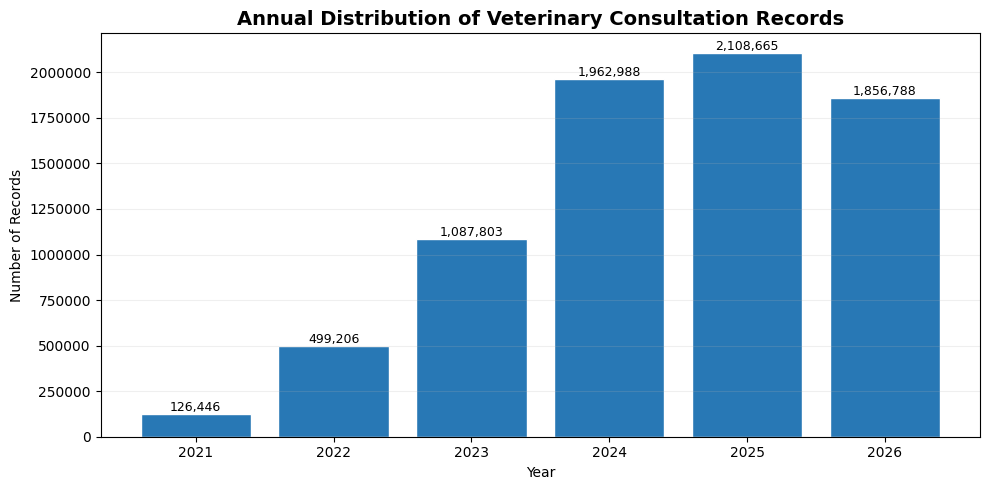

,Records
ConsultationDate,
2021,126446
2022,499206
2023,1087803
2024,1962988
2025,2108665
2026,1856788


In [11]:
# ============================================================
# 5.1 ANNUAL CONSULTATION RECORD DISTRIBUTION
# ============================================================

annual_counts = (
    cleaned_df
    .groupby(cleaned_df["ConsultationDate"].dt.year)
    .size()
    .sort_index()
)

plt.figure(figsize=(10, 5))

bars = plt.bar(
    annual_counts.index.astype(str),
    annual_counts.values,
    color="#2878B5",
    edgecolor="white"
)

plt.title(
    "Annual Distribution of Veterinary Consultation Records",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Year")
plt.ylabel("Number of Records")

plt.grid(axis="y", alpha=0.2)
plt.ticklabel_format(style="plain", axis="y")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():,}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.show()

display(annual_counts.to_frame("Records"))

### 5.2 Monthly Consultation Record Trends

Monthly consultation record volumes were examined to
understand the temporal distribution of the combined
historical dataset.

This analysis helps identify changes in data coverage,
potential seasonal patterns, and differences in recorded
consultation activity over time.

These results represent all available clinic records
before SEQ geographical filtering and tick-related
consultation identification.

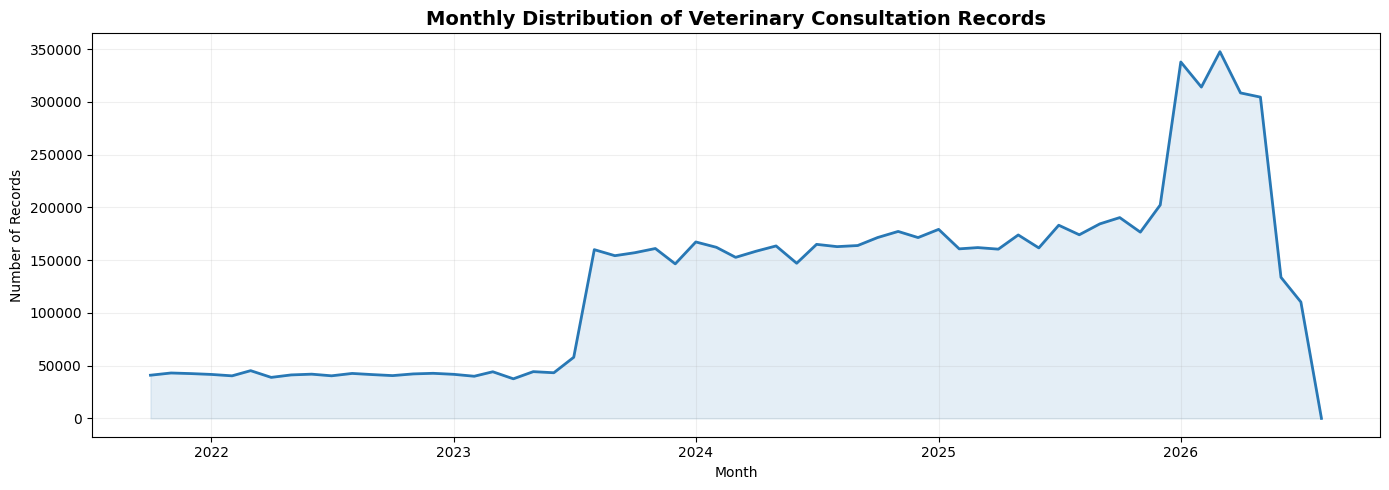

Total months: 59
Highest-volume month: 2026-03
Lowest-volume month: 2026-08


In [12]:
# ============================================================
# 5.2 MONTHLY CONSULTATION RECORD TRENDS
# ============================================================

monthly_counts = (
    cleaned_df
    .groupby(
        cleaned_df["ConsultationDate"].dt.to_period("M")
    )
    .size()
    .sort_index()
)

monthly_counts.index = monthly_counts.index.to_timestamp()

plt.figure(figsize=(14, 5))

plt.plot(
    monthly_counts.index,
    monthly_counts.values,
    color="#2878B5",
    linewidth=2
)

plt.fill_between(
    monthly_counts.index,
    monthly_counts.values,
    alpha=0.12,
    color="#2878B5"
)

plt.title(
    "Monthly Distribution of Veterinary Consultation Records",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Number of Records")

plt.grid(alpha=0.2)
plt.ticklabel_format(style="plain", axis="y")

plt.tight_layout()
plt.show()

print("Total months:", len(monthly_counts))
print("Highest-volume month:", monthly_counts.idxmax().strftime("%Y-%m"))
print("Lowest-volume month:", monthly_counts.idxmin().strftime("%Y-%m"))

In [13]:
# ============================================================
# 5.3 MONTHLY DATA COVERAGE VALIDATION
# ============================================================

monthly_coverage = (
    cleaned_df
    .groupby(cleaned_df["ConsultationDate"].dt.to_period("M"))
    .agg(
        Records=("ConsultationKey", "size"),
        Active_Clinics=("ClinicID", "nunique")
    )
)

print("Monthly coverage around mid-2023:")
display(monthly_coverage.loc["2023-04":"2023-09"])

print("\nMonthly coverage during 2026:")
display(monthly_coverage.loc["2026-01":"2026-08"])

Monthly coverage around mid-2023:


,Records,Active_Clinics
ConsultationDate,,
2023-04,37521,19
2023-05,44315,20
2023-06,43262,20
2023-07,57954,65
2023-08,159965,70
2023-09,154248,70



Monthly coverage during 2026:


,Records,Active_Clinics
ConsultationDate,,
2026-01,337885,56
2026-02,314087,53
2026-03,347656,53
2026-04,308554,53
2026-05,304576,51
2026-06,133717,40
2026-07,110312,40
2026-08,1,1


## 6. Geographical Scope: South East Queensland

### 6.1 Rationale for Selecting South East Queensland

South East Queensland (SEQ) was selected as the geographical
focus of this study to investigate tick-related veterinary
consultation demand within a relatively consistent regional
setting.

The region experiences climatic conditions relevant to tick
activity, making it suitable for examining associations
between veterinary consultation patterns and environmental
variables such as temperature, rainfall, and humidity.

Restricting the analysis to SEQ also supports the integration
of clinic-level consultation records with location-specific
weather data obtained from Open-Meteo and Queensland-level
Google Trends search interest.

The geographical restriction helps reduce broad climatic
variation between regions and provides a defined population
for evaluating two-week-ahead forecasting models.

Only clinics with verified locations within the selected
SEQ study area will be included in the regional forecasting
analysis.

In [14]:
# ============================================================
# 6.1 GEOGRAPHICAL COVERAGE OF COMBINED VETIQ DATASET
# ============================================================

clinics_reference = pd.read_csv(
    PROJECT_DIR / "Tick Analysis/Clinics.csv"
)

clinic_summary = (
    cleaned_df.groupby("ClinicID")
    .agg(
        Total_Records=("ConsultationKey", "size"),
        First_Date=("ConsultationDate", "min"),
        Last_Date=("ConsultationDate", "max")
    )
    .reset_index()
)

clinic_summary = clinic_summary.merge(
    clinics_reference[
        ["ClinicID", "SuburbName", "StateCode"]
    ],
    on="ClinicID",
    how="left"
)

print("Total clinics in combined dataset:",
      clinic_summary["ClinicID"].nunique())

print("Clinics with geographical information:",
      clinic_summary["SuburbName"].notna().sum())

print("Clinics without geographical information:",
      clinic_summary["SuburbName"].isna().sum())

display(clinic_summary.head(15))

Total clinics in combined dataset: 78
Clinics with geographical information: 26
Clinics without geographical information: 52


,ClinicID,Total_Records,First_Date,Last_Date,SuburbName,StateCode
0,1,149878,2023-07-27,2026-07-25,NaN,NaN
1,2,104108,2023-07-27,2025-12-02,NaN,NaN
2,3,128718,2023-07-27,2026-07-26,NaN,NaN
3,4,139251,2023-07-27,2026-07-24,NaN,NaN
4,5,82519,2023-07-27,2026-07-25,NaN,NaN
5,6,63875,2023-07-27,2026-07-25,NaN,NaN
6,7,56887,2023-07-27,2026-07-26,NaN,NaN
7,8,138233,2021-10-01,2026-04-28,D******** B**,QLD
8,10,66,2023-08-31,2026-04-21,NaN,NaN
9,11,14140,2023-07-27,2025-01-09,NaN,NaN


In [15]:
# ============================================================
# 6.2 COMPLETE CLINIC GEOGRAPHICAL COVERAGE
# ============================================================

mapping_df = pd.read_csv(
    PROJECT_DIR / "clinic_weather_mapping.csv"
)

# Convert pseudonym to numeric ClinicID
mapping_df["ClinicID"] = pd.to_numeric(
    mapping_df["ClinicPseudonym"]
    .astype("string")
    .str.replace(r"^Clinic_", "", regex=True),
    errors="coerce"
).astype("Int64")

# Keep one geographical mapping per clinic
geo_mapping = mapping_df[
    ["ClinicID", "Postcode", "Suburb",
     "latitude", "longitude"]
].drop_duplicates(subset=["ClinicID"])

# Add geographical details to the existing clinic summary
clinic_geo = clinic_summary.merge(
    geo_mapping,
    on="ClinicID",
    how="left",
    validate="one_to_one"
)

print("=" * 60)
print("COMBINED VETIQ CLINIC GEOGRAPHICAL COVERAGE")
print("=" * 60)

print("Total clinics:", len(clinic_geo))

print("Clinics with mapped suburbs:",
      clinic_geo["Suburb"].notna().sum())

print("Clinics with original reference information:",
      clinic_geo["SuburbName"].notna().sum())

print("Clinics without either location reference:",
      (
          clinic_geo["Suburb"].isna()
          & clinic_geo["SuburbName"].isna()
      ).sum())

print("\nMapped clinic locations:")
display(
    clinic_geo[
        ["ClinicID", "Total_Records",
         "Suburb", "Postcode",
         "SuburbName", "StateCode"]
    ].sort_values("ClinicID")
)

COMBINED VETIQ CLINIC GEOGRAPHICAL COVERAGE
Total clinics: 78
Clinics with mapped suburbs: 58
Clinics with original reference information: 26
Clinics without either location reference: 0

Mapped clinic locations:


,ClinicID,Total_Records,Suburb,Postcode,SuburbName,StateCode
0,1,149878,Deception Bay,4508.0,NaN,NaN
1,2,104108,Yeppoon,4703.0,NaN,NaN
2,3,128718,Augustine Heights,4300.0,NaN,NaN
3,4,139251,Redbank Plains,4301.0,NaN,NaN
4,5,82519,Springfield,4300.0,NaN,NaN
...,...,...,...,...,...,...
73,154,151063,NaN,NaN,T****** B****,QLD
74,176,63215,NaN,NaN,S********,QLD
75,241,57122,NaN,NaN,C***** B****,QLD
76,329,36231,NaN,NaN,V*******,QLD


In [16]:

# STEP 5E — CHECK LOCATION COVERAGE OF SELECTED CLINICS

import pandas as pd

# Find DataFrames containing the geographical mapping
for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        required = {"ClinicID", "Suburb", "Postcode"}

        if required.issubset(obj.columns):
            print(
                name,
                "| rows:", len(obj),
                "| clinics:", obj["ClinicID"].nunique()
            )


mapping_df | rows: 62 | clinics: 62
geo_mapping | rows: 62 | clinics: 62
clinic_geo | rows: 78 | clinics: 78


### 6.3 Geographical Distribution of VetIQ Clinics

The geographical distribution of participating clinics was
examined to assess whether South East Queensland represents
a suitable regional focus for the study.

Clinic location information was linked to the combined
consultation dataset using clinic identifiers.

An initial geographical visualisation was produced using
clinics with available latitude and longitude coordinates.
This analysis supports the assessment of clinic concentration
before finalising the regional study population.

Clinics with coordinates: 58
Clinics without coordinates: 20


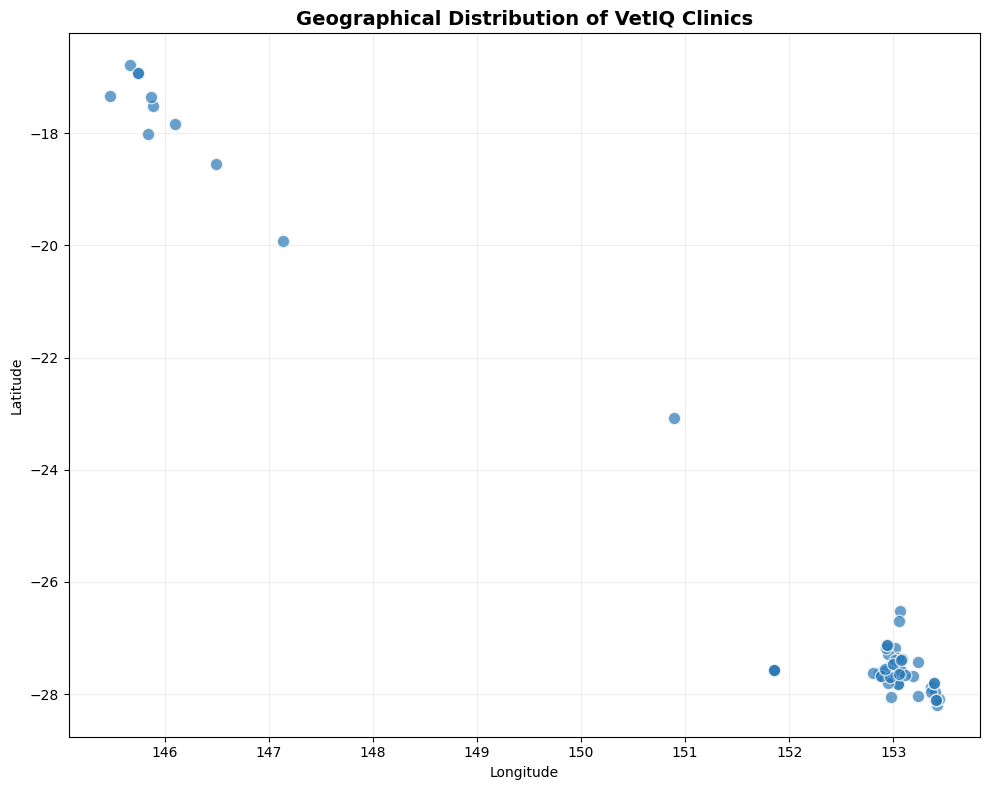

In [18]:
# ============================================================
# 6.3 GEOGRAPHICAL DISTRIBUTION OF VETIQ CLINICS
# ============================================================

geo_plot = clinic_geo.dropna(
    subset=["latitude", "longitude"]
).copy()

print("Clinics with coordinates:", len(geo_plot))
print("Clinics without coordinates:",
      len(clinic_geo) - len(geo_plot))

plt.figure(figsize=(10, 8))

plt.scatter(
    geo_plot["longitude"],
    geo_plot["latitude"],
    s=80,
    alpha=0.7,
    color="#2878B5",
    edgecolor="white"
)

plt.title(
    "Geographical Distribution of VetIQ Clinics",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [19]:
# ============================================================
# 6.4 PRELIMINARY SEQ CLINIC CONCENTRATION
# ============================================================

geo_plot["SEQ_Preliminary"] = (
    geo_plot["latitude"].between(-28.5, -26.0)
    & geo_plot["longitude"].between(151.5, 153.7)
)

seq_clinics = geo_plot["SEQ_Preliminary"].sum()
total_mapped = len(geo_plot)

print("Total mapped clinics:", total_mapped)
print("Clinics within preliminary SEQ boundary:", seq_clinics)
print("Clinics outside preliminary SEQ boundary:",
      total_mapped - seq_clinics)

print(
    "Percentage within preliminary SEQ boundary:",
    round(seq_clinics / total_mapped * 100, 2), "%"
)

print("\nConsultation record distribution:")

display(
    geo_plot.groupby("SEQ_Preliminary")
    .agg(
        Clinics=("ClinicID", "nunique"),
        Consultation_Records=("Total_Records", "sum")
    )
)

Total mapped clinics: 58
Clinics within preliminary SEQ boundary: 47
Clinics outside preliminary SEQ boundary: 11
Percentage within preliminary SEQ boundary: 81.03 %

Consultation record distribution:


,Clinics,Consultation_Records
SEQ_Preliminary,,
False,11,1371817
True,47,5365634


### 6.5 Data-Driven Justification for Selecting South East Queensland

The selection of South East Queensland (SEQ) was informed by
an exploratory geographical assessment of the combined VetIQ
consultation dataset.

Of the 78 clinics represented in the combined dataset,
58 had available geographical coordinates. Using a
preliminary geographical boundary for SEQ, 47 of these
58 clinics (81.03%) were located within the study area.

These 47 clinics contributed 5,365,634 consultation records,
representing approximately 79.64% of the records associated
with geographically mapped clinics.

This demonstrates a substantial concentration of both
participating clinics and available consultation records
within the preliminary SEQ study area.

Consequently, SEQ was identified as a suitable regional
focus for investigating tick-related veterinary demand,
seasonal patterns, and relationships with environmental
factors.

The preliminary geographical classification will be
validated against the defined SEQ regional boundary
before finalising the study population.

In [22]:

import pandas as pd
import numpy as np

# Work from the cleaned combined consultations
seq_source = cleaned_df.copy()

# Check that the required fields exist
required = ["ClinicID", "ConsultationDate"]
assert all(c in seq_source.columns for c in required)

# Convert dates
seq_source["ConsultationDate"] = pd.to_datetime(
    seq_source["ConsultationDate"], errors="coerce"
)

# Keep records with a valid clinic and date
seq_source = seq_source.dropna(
    subset=["ClinicID", "ConsultationDate"]
)

# Create Sunday-ending consultation weeks
seq_source["WeekEnding"] = (
    seq_source["ConsultationDate"]
    .dt.to_period("W-SUN")
    .dt.end_time
    .dt.normalize()
)

# IMPORTANT:
# Do not invent Tick_Records using a new keyword rule.
# First check whether an existing tick classification exists.
print("Available columns:")
print(seq_source.columns.tolist())

print("\nTotal records:", len(seq_source))
print("Clinics:", seq_source["ClinicID"].nunique())
print("Weeks:", seq_source["WeekEnding"].nunique())

print("\nFirst five rows:")
display(seq_source.head())


Available columns:
['ConsultationKey', 'ClinicID', 'ClinicPseudonym', 'ConsultationDate', 'ItemServiceFeeName', 'ExaminationTextString', 'SummaryString', 'SpecialInstructionString', 'DataSource', 'WeekEnding']

Total records: 7641896
Clinics: 78
Weeks: 253

First five rows:


,ConsultationKey,ClinicID,ClinicPseudonym,ConsultationDate,ItemServiceFeeName,ExaminationTextString,SummaryString,SpecialInstructionString,DataSource,WeekEnding
0,A726C982F0D077B2DBDA21FA915EF54B4E6C503BC9BEC1...,8,Clinic_08,2021-10-01,Standard Fee,NaN,NaN,NaN,Consultation.csv,2021-10-03
1,37BDEB8EE25F1103F14F312F351F32BE25CBB908F2E9F9...,8,Clinic_08,2021-10-01,Standard Fee,NaN,NaN,NaN,Consultation.csv,2021-10-03
2,9914B7E657C41B48039E8F87F2453BAF4E0F6750190834...,8,Clinic_08,2021-10-01,Standard Fee,NaN,NaN,NaN,Consultation.csv,2021-10-03
3,1F0BE8BD616A94C4F33374337396824196BEFDC2975192...,8,Clinic_08,2021-10-01,Standard Fee,NaN,NaN,NaN,Consultation.csv,2021-10-03
4,08BDFDE5077878933F768190667CDD82D33D4B60C9C193...,8,Clinic_08,2021-10-01,1st Animal,NaN,NaN,NaN,Consultation.csv,2021-10-03


In [24]:

import pandas as pd

print("=== CONSULTATION DATA AUDIT ===")

print("\nRecords by source:")
print(seq_source["DataSource"].value_counts(dropna=False))

print("\nConsultation key completeness:")
print("Total rows:", len(seq_source))
print("Missing keys:", seq_source["ConsultationKey"].isna().sum())
print("Unique keys:", seq_source["ConsultationKey"].nunique())
print("Duplicate key rows:",
      seq_source["ConsultationKey"].duplicated().sum())

print("\nRecords with tick mentions by text field:")
text_columns = [
    "ItemServiceFeeName",
    "ExaminationTextString",
    "SummaryString",
    "SpecialInstructionString"
]

for col in text_columns:
    mentions = seq_source[col].astype("string").str.contains(
        r"\bticks?\b",
        case=False,
        regex=True,
        na=False
    )
    print(f"{col}: {mentions.sum():,}")

print("\nExisting tick-related variables:")
for name in sorted(globals()):
    if "tick" in name.lower():
        obj = globals()[name]
        if isinstance(obj, pd.DataFrame):
            print(name, "->", len(obj), "rows",
                  list(obj.columns)[:15])
        else:
            print(name, "->", type(obj).__name__)


=== CONSULTATION DATA AUDIT ===

Records by source:
DataSource
consultations_freetext.csv    6593321
Consultation.csv              1048575
Name: count, dtype: int64

Consultation key completeness:
Total rows: 7641896
Missing keys: 0
Unique keys: 7036110
Duplicate key rows: 605786

Records with tick mentions by text field:
ItemServiceFeeName: 111
ExaminationTextString: 445,987
SummaryString: 4,103
SpecialInstructionString: 0

Existing tick-related variables:


In [26]:

import pandas as pd

print("=== CONSULTATION KEY DUPLICATE AUDIT ===")

# Count repeated consultation keys
key_counts = (
    seq_source.groupby("ConsultationKey")
    .size()
)

print("\nKeys appearing more than once:",
      (key_counts > 1).sum())

print("Maximum rows per key:",
      key_counts.max())

# Check whether the same key belongs to multiple clinics
clinic_counts = (
    seq_source.groupby("ConsultationKey")["ClinicID"]
    .nunique()
)

print("\nKeys associated with multiple clinics:",
      (clinic_counts > 1).sum())

# Check whether the same key appears on multiple dates
date_counts = (
    seq_source.groupby("ConsultationKey")["ConsultationDate"]
    .nunique()
)

print("Keys associated with multiple dates:",
      (date_counts > 1).sum())

# Examine the sources for repeated keys
repeated_keys = key_counts[key_counts > 1].index

duplicate_sample = seq_source.loc[
    seq_source["ConsultationKey"].isin(
        repeated_keys[:5]
    ),
    [
        "ConsultationKey",
        "ClinicID",
        "ConsultationDate",
        "DataSource",
        "ItemServiceFeeName",
        "ExaminationTextString"
    ]
]

display(duplicate_sample)


=== CONSULTATION KEY DUPLICATE AUDIT ===

Keys appearing more than once: 602223
Maximum rows per key: 3

Keys associated with multiple clinics: 602223
Keys associated with multiple dates: 600654


,ConsultationKey,ClinicID,ConsultationDate,DataSource,ItemServiceFeeName,ExaminationTextString
2022714,00002B0A399DF99EFAB911FE55AF0F51888252E769060C...,2,2024-08-16,consultations_freetext.csv,NaN,"Reason: Gabapentin, Meloxicam Approved by DL ..."
2217518,0000168060B02C808DDB08187E69695B042EB2E6E12A4C...,5,2024-10-21,consultations_freetext.csv,NaN,Here for sedated groom Sedation: Medetomidine ...
4292888,0000226A14C11C5251336C7DC50695105804C6A4C9D21E...,23,2026-02-23,consultations_freetext.csv,NaN,NaN
4931061,000008B9599840996D6FBD7091E1B439CDFB911C5362E1...,40,2025-01-21,consultations_freetext.csv,NaN,NaN
5044248,000014C8D892B7D7E6E703CFFC88B54189B40CA747C8D4...,38,2025-04-28,consultations_freetext.csv,NaN,NaN
5634456,000008B9599840996D6FBD7091E1B439CDFB911C5362E1...,45,2024-02-02,consultations_freetext.csv,NaN,NaN
5792169,000014C8D892B7D7E6E703CFFC88B54189B40CA747C8D4...,45,2024-09-23,consultations_freetext.csv,NaN,NaN
7308801,00002B0A399DF99EFAB911FE55AF0F51888252E769060C...,44,2024-08-23,consultations_freetext.csv,NaN,NaN
7353419,0000226A14C11C5251336C7DC50695105804C6A4C9D21E...,50,2024-11-21,consultations_freetext.csv,NaN,NaN
7592225,0000168060B02C808DDB08187E69695B042EB2E6E12A4C...,44,2026-03-09,consultations_freetext.csv,NaN,NaN


In [27]:

import pandas as pd

print("=== CONSULTATION KEY SOURCE AUDIT ===")

# Identify how many distinct sources contain each key
key_sources = (
    seq_source
    .groupby("ConsultationKey")["DataSource"]
    .nunique()
)

print("Keys appearing in multiple sources:",
      (key_sources > 1).sum())

# Examine duplicates within each source
for source, df in seq_source.groupby("DataSource"):
    print(f"\nSource: {source}")
    print("Rows:", len(df))
    print("Unique keys:", df["ConsultationKey"].nunique())
    print("Repeated key rows:",
          df["ConsultationKey"].duplicated().sum())

# Check whether the combination of clinic, date and key
# is more reliable than ConsultationKey alone
composite_columns = [
    "ClinicID",
    "ConsultationDate",
    "ConsultationKey"
]

print("\n=== COMPOSITE IDENTIFIER CHECK ===")

print(
    "Unique clinic-date-key combinations:",
    len(seq_source.drop_duplicates(subset=composite_columns))
)

print(
    "Repeated clinic-date-key rows:",
    seq_source.duplicated(subset=composite_columns).sum()
)


=== CONSULTATION KEY SOURCE AUDIT ===
Keys appearing in multiple sources: 0

Source: Consultation.csv
Rows: 1048575
Unique keys: 1048575
Repeated key rows: 0

Source: consultations_freetext.csv
Rows: 6593321
Unique keys: 5987535
Repeated key rows: 605786

=== COMPOSITE IDENTIFIER CHECK ===
Unique clinic-date-key combinations: 7641896
Repeated clinic-date-key rows: 0


In [28]:

import pandas as pd

eligible_ids = [
    1, 3, 4, 5, 6, 7, 12, 13,
    14, 15, 16, 17, 18, 19,
    20, 27, 28, 30, 31, 47,
    52, 54, 58, 59
]

print("=== WEATHER LOCATION MAPPING AUDIT ===")

mapping_check = mapping_df[
    mapping_df["ClinicID"].isin(eligible_ids)
].copy()

print("Expected clinics:", len(eligible_ids))

print(
    "Clinics found in mapping:",
    mapping_check["ClinicID"].nunique()
)

print("\nMissing clinic IDs:")
print(
    sorted(
        set(eligible_ids)
        - set(mapping_check["ClinicID"].dropna())
    )
)

print("\nClinics with multiple mapping rows:")
multiple = mapping_check.groupby("ClinicID").size()
print(multiple[multiple > 1])

print("\nMapping details:")
display(
    mapping_check[
        [
            "ClinicID",
            "Suburb",
            "Postcode",
            "WeatherLocationID",
            "latitude",
            "longitude"
        ]
    ].sort_values("ClinicID")
)


=== WEATHER LOCATION MAPPING AUDIT ===
Expected clinics: 24
Clinics found in mapping: 24

Missing clinic IDs:
[]

Clinics with multiple mapping rows:
Series([], dtype: int64)

Mapping details:


,ClinicID,Suburb,Postcode,WeatherLocationID,latitude,longitude
0,1,Deception Bay,4508,Weather_01,-27.181203,153.013716
2,3,Augustine Heights,4300,Weather_03,-27.682273,152.884999
3,4,Redbank Plains,4301,Weather_04,-27.629394,152.858086
4,5,Springfield,4300,Weather_03,-27.682273,152.884999
5,6,Greenbank,4124,Weather_05,-27.701681,152.967761
6,7,North MacLean,4280,Weather_06,-27.816090,153.048563
11,12,Bardon,4065,Weather_11,-27.462504,152.975992
12,13,Ashgrove,4060,Weather_12,-27.445107,152.985176
13,14,Jimboomba,4280,Weather_06,-27.816090,153.048563
14,15,Miami,4220,Weather_13,-28.084952,153.434406


In [29]:
 
import pandas as pd

print("=== WEATHER MAPPING VALIDATION ===")

# Check missing mapping values
cols = [
    "ClinicID", "WeatherLocationID",
    "latitude", "longitude"
]

print("\nMissing values:")
print(mapping_check[cols].isna().sum())

# Count unique weather locations
print("\nUnique weather locations:",
      mapping_check["WeatherLocationID"].nunique())

# Check whether one weather ID points to different coordinates
coordinate_check = (
    mapping_check.groupby("WeatherLocationID")
    .agg(
        Latitude_Count=("latitude", "nunique"),
        Longitude_Count=("longitude", "nunique")
    )
)

conflicts = coordinate_check[
    (coordinate_check["Latitude_Count"] > 1) |
    (coordinate_check["Longitude_Count"] > 1)
]

print("\nWeather IDs with conflicting coordinates:")
display(conflicts)

# Check coordinate ranges
invalid_coordinates = mapping_check[
    ~mapping_check["latitude"].between(-90, 90) |
    ~mapping_check["longitude"].between(-180, 180)
]

print("\nInvalid coordinates:",
      len(invalid_coordinates))

# Show shared weather locations
shared_locations = (
    mapping_check.groupby("WeatherLocationID")
    .agg(
        Clinic_Count=("ClinicID", "nunique"),
        Clinic_IDs=("ClinicID", lambda x: sorted(x.tolist()))
    )
)

print("\nWeather locations shared by clinics:")
display(
    shared_locations[
        shared_locations["Clinic_Count"] > 1
    ]
)


=== WEATHER MAPPING VALIDATION ===

Missing values:
ClinicID             0
WeatherLocationID    0
latitude             0
longitude            0
dtype: int64

Unique weather locations: 20

Weather IDs with conflicting coordinates:


,Latitude_Count,Longitude_Count
WeatherLocationID,,



Invalid coordinates: 0

Weather locations shared by clinics:


,Clinic_Count,Clinic_IDs
WeatherLocationID,,
Weather_03,2,"[3, 5]"
Weather_05,2,"[6, 31]"
Weather_06,2,"[7, 14]"
Weather_07,2,"[20, 52]"


In [30]:

import pandas as pd

print("=== EXISTING WEATHER DATA CHECK ===")

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        weather_columns = [
            col for col in obj.columns
            if any(term in col.lower() for term in [
                "weather", "temp", "rain",
                "humidity", "precip"
            ])
        ]

        if weather_columns:
            print(f"\n{name}: {len(obj):,} rows")
            print("Weather columns:", weather_columns)
            print("All columns:", obj.columns.tolist())


=== EXISTING WEATHER DATA CHECK ===

consultation_df: 1,048,575 rows
Weather columns: ['ConsultationTemperatureDecimal']
All columns: ['ConsultationKey', 'ClientKey', 'PatientKey', 'ClinicID', 'ConsultingVetUserID', 'ConsultationDate', 'ConsultationDateTime', 'ItemServiceFeeName', 'ItemServiceQty', 'TotalSalePriceAmt', 'TotalTaxAmt', 'ConsultationWeightDecimal', 'ConsultationTemperatureDecimal']

mapping_df: 62 rows
Weather columns: ['WeatherLocationID']
All columns: ['ClinicPseudonym', 'Postcode', 'Suburb', 'WeatherLocationID', 'latitude', 'longitude', 'ClinicID']

mapping_check: 24 rows
Weather columns: ['WeatherLocationID']
All columns: ['ClinicPseudonym', 'Postcode', 'Suburb', 'WeatherLocationID', 'latitude', 'longitude', 'ClinicID']

invalid_coordinates: 0 rows
Weather columns: ['WeatherLocationID']
All columns: ['ClinicPseudonym', 'Postcode', 'Suburb', 'WeatherLocationID', 'latitude', 'longitude', 'ClinicID']


In [31]:

import pandas as pd

print("=== PREPARE WEATHER LOCATIONS ===")

weather_locations = (
    mapping_check[
        ["WeatherLocationID", "latitude", "longitude"]
    ]
    .drop_duplicates()
    .sort_values("WeatherLocationID")
    .reset_index(drop=True)
)

assert len(weather_locations) == 20, (
    "Expected 20 unique weather locations."
)

assert (
    weather_locations["WeatherLocationID"].is_unique
), "Duplicate WeatherLocationID detected."

print("Unique weather locations:", len(weather_locations))

display(weather_locations)

weather_locations.to_csv(
    "weather_locations_24clinics.csv",
    index=False
)

print("\nSaved: weather_locations_24clinics.csv")


=== PREPARE WEATHER LOCATIONS ===
Unique weather locations: 20


,WeatherLocationID,latitude,longitude
0,Weather_01,-27.181203,153.013716
1,Weather_03,-27.682273,152.884999
2,Weather_04,-27.629394,152.858086
3,Weather_05,-27.701681,152.967761
4,Weather_06,-27.816090,153.048563
5,Weather_07,-27.576308,151.852689
6,Weather_11,-27.462504,152.975992
7,Weather_12,-27.445107,152.985176
8,Weather_13,-28.084952,153.434406
9,Weather_14,-27.869823,153.360694



Saved: weather_locations_24clinics.csv


In [32]:

import pandas as pd
import requests
import time

print("=== DOWNLOADING HISTORICAL WEATHER ===")

url = "https://archive-api.open-meteo.com/v1/archive"

all_weather = []
failed_locations = []

for _, loc in weather_locations.iterrows():
    location_id = loc["WeatherLocationID"]

    params = {
        "latitude": float(loc["latitude"]),
        "longitude": float(loc["longitude"]),
        "start_date": "2023-07-23",
        "end_date": "2026-07-26",
        "daily": [
            "temperature_2m_mean",
            "precipitation_sum"
        ],
        "hourly": "relative_humidity_2m",
        "timezone": "Australia/Brisbane"
    }

    try:
        response = requests.get(
            url, params=params, timeout=90
        )
        response.raise_for_status()
        data = response.json()

        daily = pd.DataFrame(data["daily"])
        daily["Date"] = pd.to_datetime(daily["time"])

        hourly = pd.DataFrame(data["hourly"])
        hourly["Date"] = pd.to_datetime(
            hourly["time"]
        ).dt.normalize()

        humidity = (
            hourly.groupby("Date", as_index=False)
            ["relative_humidity_2m"]
            .mean()
        )

        daily = daily.merge(
            humidity, on="Date", how="left"
        )

        daily["WeatherLocationID"] = location_id

        all_weather.append(
            daily[
                [
                    "WeatherLocationID",
                    "Date",
                    "temperature_2m_mean",
                    "precipitation_sum",
                    "relative_humidity_2m"
                ]
            ]
        )

        print(f"Downloaded: {location_id}")
        time.sleep(0.3)

    except Exception as e:
        failed_locations.append(location_id)
        print(f"FAILED: {location_id} -> {e}")

if not all_weather:
    raise RuntimeError("No weather data downloaded.")

weather_daily = pd.concat(
    all_weather, ignore_index=True
)

weather_daily = weather_daily.rename(
    columns={
        "temperature_2m_mean": "AvgTemp_C",
        "precipitation_sum": "Rainfall_mm",
        "relative_humidity_2m": "Humidity_pct"
    }
)

print("\n=== DOWNLOAD SUMMARY ===")
print("Rows:", len(weather_daily))
print("Locations:",
      weather_daily["WeatherLocationID"].nunique())
print("Date range:",
      weather_daily["Date"].min(),
      "to",
      weather_daily["Date"].max())
print("Failed locations:", failed_locations)

weather_daily.to_csv(
    "weather_daily_24clinics.csv",
    index=False
)

display(weather_daily.head())


=== DOWNLOADING HISTORICAL WEATHER ===
Downloaded: Weather_01
Downloaded: Weather_03
Downloaded: Weather_04
Downloaded: Weather_05
Downloaded: Weather_06
Downloaded: Weather_07
Downloaded: Weather_11
Downloaded: Weather_12
Downloaded: Weather_13
Downloaded: Weather_14
Downloaded: Weather_15
Downloaded: Weather_16
Downloaded: Weather_17
Downloaded: Weather_22
Downloaded: Weather_23
Downloaded: Weather_25
Downloaded: Weather_38
Downloaded: Weather_44
Downloaded: Weather_46
Downloaded: Weather_47

=== DOWNLOAD SUMMARY ===
Rows: 22000
Locations: 20
Date range: 2023-07-23 00:00:00 to 2026-07-26 00:00:00
Failed locations: []


,WeatherLocationID,Date,AvgTemp_C,Rainfall_mm,Humidity_pct
0,Weather_01,2023-07-23,15.1,0.0,66.916667
1,Weather_01,2023-07-24,16.3,0.2,65.958333
2,Weather_01,2023-07-25,16.8,0.0,61.958333
3,Weather_01,2023-07-26,16.5,0.0,70.375000
4,Weather_01,2023-07-27,16.9,0.0,69.791667


In [33]:

import pandas as pd

print("=== WEEKLY WEATHER AGGREGATION ===")

weather_daily["Date"] = pd.to_datetime(weather_daily["Date"])

weather_daily["WeekEnding"] = (
    weather_daily["Date"]
    .dt.to_period("W-SUN")
    .dt.end_time
    .dt.normalize()
)

weather_weekly = (
    weather_daily
    .groupby(
        ["WeatherLocationID", "WeekEnding"],
        as_index=False
    )
    .agg(
        AvgTemp_C=("AvgTemp_C", "mean"),
        Rainfall_mm=("Rainfall_mm", "sum"),
        Humidity_pct=("Humidity_pct", "mean"),
        Days_Observed=("Date", "nunique")
    )
)

print("Total weekly weather rows:", len(weather_weekly))
print("Weather locations:",
      weather_weekly["WeatherLocationID"].nunique())

print("Week range:",
      weather_weekly["WeekEnding"].min(),
      "to",
      weather_weekly["WeekEnding"].max())

print("\nDays observed per week:")
print(
    weather_weekly["Days_Observed"]
    .value_counts()
    .sort_index()
)

print("\nMissing weather values:")
print(
    weather_weekly[
        ["AvgTemp_C", "Rainfall_mm", "Humidity_pct"]
    ].isna().sum()
)

display(weather_weekly.head())

weather_weekly.to_csv(
    "weather_weekly_24clinics.csv",
    index=False
)

print("\nSaved: weather_weekly_24clinics.csv")


=== WEEKLY WEATHER AGGREGATION ===
Total weekly weather rows: 3160
Weather locations: 20
Week range: 2023-07-23 00:00:00 to 2026-07-26 00:00:00

Days observed per week:
Days_Observed
1      20
7    3140
Name: count, dtype: int64

Missing weather values:
AvgTemp_C       0
Rainfall_mm     0
Humidity_pct    0
dtype: int64


,WeatherLocationID,WeekEnding,AvgTemp_C,Rainfall_mm,Humidity_pct,Days_Observed
0,Weather_01,2023-07-23,15.100000,0.0,66.916667,1
1,Weather_01,2023-07-30,16.571429,0.2,69.404762,7
2,Weather_01,2023-08-06,17.471429,6.8,76.678571,7
3,Weather_01,2023-08-13,16.928571,1.3,68.660714,7
4,Weather_01,2023-08-20,18.128571,0.9,59.892857,7



Saved: weather_weekly_24clinics.csv


In [34]:

import pandas as pd

print("=== CLINIC-WEEKLY WEATHER MAPPING ===")

# Retain only complete 7-day weeks
weather_weekly_complete = weather_weekly[
    weather_weekly["Days_Observed"] == 7
].copy()

# One mapping row per clinic
clinic_weather_map = mapping_check[
    ["ClinicID", "WeatherLocationID"]
].copy()

assert clinic_weather_map["ClinicID"].is_unique
assert weather_weekly_complete[
    ["WeatherLocationID", "WeekEnding"]
].duplicated().sum() == 0

# Expand weather observations to clinic-week level
clinic_weekly_weather = clinic_weather_map.merge(
    weather_weekly_complete,
    on="WeatherLocationID",
    how="left",
    validate="many_to_many"
)

print("Clinics:",
      clinic_weekly_weather["ClinicID"].nunique())

print("Weeks:",
      clinic_weekly_weather["WeekEnding"].nunique())

print("Total clinic-week rows:",
      len(clinic_weekly_weather))

print("\nMissing weather values:")
print(
    clinic_weekly_weather[
        ["AvgTemp_C", "Rainfall_mm", "Humidity_pct"]
    ].isna().sum()
)

print("\nDuplicate clinic-week rows:")
print(
    clinic_weekly_weather.duplicated(
        ["ClinicID", "WeekEnding"]
    ).sum()
)

print("\nWeeks per clinic:")
print(
    clinic_weekly_weather.groupby("ClinicID")[
        "WeekEnding"
    ].nunique().describe()
)

display(clinic_weekly_weather.head())

clinic_weekly_weather.to_csv(
    "clinic_weekly_weather_24clinics.csv",
    index=False
)

print("\nSaved: clinic_weekly_weather_24clinics.csv")


=== CLINIC-WEEKLY WEATHER MAPPING ===
Clinics: 24
Weeks: 157
Total clinic-week rows: 3768

Missing weather values:
AvgTemp_C       0
Rainfall_mm     0
Humidity_pct    0
dtype: int64

Duplicate clinic-week rows:
0

Weeks per clinic:
count     24.0
mean     157.0
std        0.0
min      157.0
25%      157.0
50%      157.0
75%      157.0
max      157.0
Name: WeekEnding, dtype: float64


,ClinicID,WeatherLocationID,WeekEnding,AvgTemp_C,Rainfall_mm,Humidity_pct,Days_Observed
0,1,Weather_01,2023-07-30,16.571429,0.2,69.404762,7
1,1,Weather_01,2023-08-06,17.471429,6.8,76.678571,7
2,1,Weather_01,2023-08-13,16.928571,1.3,68.660714,7
3,1,Weather_01,2023-08-20,18.128571,0.9,59.892857,7
4,1,Weather_01,2023-08-27,17.885714,1.2,72.684524,7



Saved: clinic_weekly_weather_24clinics.csv


In [35]:

import pandas as pd

print("=== CONSULTATION COVERAGE FOR 24 CLINICS ===")

consultation_coverage = seq_source[
    seq_source["ClinicID"].isin(
        clinic_weekly_weather["ClinicID"].unique()
    )
    & seq_source["WeekEnding"].between(
        pd.Timestamp("2023-07-30"),
        pd.Timestamp("2026-07-26")
    )
].copy()

clinic_coverage_audit = (
    consultation_coverage
    .groupby("ClinicID", as_index=False)
    .agg(
        Consultation_Rows=("ConsultationKey", "size"),
        Observed_Weeks=("WeekEnding", "nunique"),
        First_Week=("WeekEnding", "min"),
        Last_Week=("WeekEnding", "max")
    )
)

print("Consultation rows:",
      len(consultation_coverage))

print("Clinics with consultation records:",
      clinic_coverage_audit["ClinicID"].nunique())

print("\nCoverage by clinic:")
display(
    clinic_coverage_audit.sort_values("ClinicID")
)

print("\nClinics without consultation records:")
print(
    sorted(
        set(clinic_weekly_weather["ClinicID"])
        - set(clinic_coverage_audit["ClinicID"])
    )
)


=== CONSULTATION COVERAGE FOR 24 CLINICS ===
Consultation rows: 2417749
Clinics with consultation records: 24

Coverage by clinic:


,ClinicID,Consultation_Rows,Observed_Weeks,First_Week,Last_Week
0,1,149878,157,2023-07-30,2026-07-26
1,3,128718,157,2023-07-30,2026-07-26
2,4,139251,157,2023-07-30,2026-07-26
3,5,82519,157,2023-07-30,2026-07-26
4,6,63875,157,2023-07-30,2026-07-26
5,7,56887,157,2023-07-30,2026-07-26
6,12,70412,157,2023-07-30,2026-07-26
7,13,135857,157,2023-07-30,2026-07-26
8,14,59888,157,2023-07-30,2026-07-26
9,15,94838,157,2023-07-30,2026-07-26



Clinics without consultation records:
[]


In [36]:

print("=== CONSULTATION SOURCE COVERAGE ===")

source_coverage = (
    consultation_coverage
    .groupby(["ClinicID", "DataSource"])
    .agg(
        Rows=("ConsultationKey", "size"),
        Weeks=("WeekEnding", "nunique"),
        First_Date=("ConsultationDate", "min"),
        Last_Date=("ConsultationDate", "max")
    )
    .reset_index()
)

display(
    source_coverage.sort_values(
        ["ClinicID", "DataSource"]
    )
)

print("\n=== TOTAL BY SOURCE ===")
display(
    consultation_coverage.groupby("DataSource")
    .agg(
        Rows=("ConsultationKey", "size"),
        Clinics=("ClinicID", "nunique"),
        Weeks=("WeekEnding", "nunique")
    )
)


=== CONSULTATION SOURCE COVERAGE ===


,ClinicID,DataSource,Rows,Weeks,First_Date,Last_Date
0,1,consultations_freetext.csv,149878,157,2023-07-27,2026-07-25
1,3,consultations_freetext.csv,128718,157,2023-07-27,2026-07-26
2,4,consultations_freetext.csv,139251,157,2023-07-27,2026-07-24
3,5,consultations_freetext.csv,82519,157,2023-07-27,2026-07-25
4,6,consultations_freetext.csv,63875,157,2023-07-27,2026-07-25
5,7,consultations_freetext.csv,56887,157,2023-07-27,2026-07-26
6,12,consultations_freetext.csv,70412,157,2023-07-27,2026-07-25
7,13,consultations_freetext.csv,135857,157,2023-07-27,2026-07-25
8,14,consultations_freetext.csv,59888,157,2023-07-27,2026-07-24
9,15,consultations_freetext.csv,94838,157,2023-07-27,2026-07-25



=== TOTAL BY SOURCE ===


,Rows,Clinics,Weeks
DataSource,,,
consultations_freetext.csv,2417749,24,157


In [37]:

import pandas as pd

print("=== TICK TEXT CLASSIFICATION AUDIT ===")

text_columns = [
    "ExaminationTextString",
    "SummaryString",
    "SpecialInstructionString"
]

# Search consultation text for tick/ticks
tick_text = (
    consultation_coverage[text_columns]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
)

tick_mention_mask = tick_text.str.contains(
    r"\bticks?\b",
    case=False,
    regex=True,
    na=False
)

tick_mentions = consultation_coverage.loc[
    tick_mention_mask
].copy()

print("Total consultation rows:",
      len(consultation_coverage))

print("Rows mentioning tick/ticks:",
      len(tick_mentions))

print("Percentage mentioning ticks:",
      round(
          100 * len(tick_mentions) /
          len(consultation_coverage),
          2
      )
)

print("\nRandom sample of 15 tick mentions:")

display(
    tick_mentions[
        [
            "ClinicID",
            "ConsultationDate",
            "ExaminationTextString",
            "SummaryString"
        ]
    ].sample(
        n=min(15, len(tick_mentions)),
        random_state=42
    )
)


=== TICK TEXT CLASSIFICATION AUDIT ===
Total consultation rows: 2417749
Rows mentioning tick/ticks: 393193
Percentage mentioning ticks: 16.26

Random sample of 15 tick mentions:


,ClinicID,ConsultationDate,ExaminationTextString,SummaryString
3240207,19,2025-09-22,Appointment Notes: Overdue reminders Arthritis...,NaN
1199005,4,2023-11-04,Legacy - Created By: Dr Rachel Wildie Legacy ...,NaN
2641986,15,2025-03-10,Reason: Pre-consult nurse initials: SC Hes b...,NaN
3784097,27,2026-03-20,20.3kg History: - due annual SR12 vacc - core...,NaN
2174541,58,2024-10-04,Reason: Lip Licking And BLL Twitching A Lot Ap...,NaN
2217662,6,2024-10-21,Appointment Notes: vacc (SM) messsage sent JM ...,NaN
2167078,3,2024-10-03,"Appointment Reason: 1. CONSULT 1, Appointment ...",Ear ( aural ) disease
3117324,12,2025-08-14,Reason: Recheck Eye Appointment Notes: Overdue...,NaN
3573423,14,2026-01-09,Reason: C5 And SR12. Lindz Appointment Notes: ...,NaN
2438830,15,2024-12-31,Reason: 2nd Vaccination Vaccination: C5 Pre-co...,NaN


In [38]:

import pandas as pd

print("=== SELECT 19 FULL-COVERAGE CLINICS ===")

full_coverage_ids = (
    clinic_coverage_audit.loc[
        clinic_coverage_audit["Observed_Weeks"] == 157,
        "ClinicID"
    ]
    .sort_values()
    .tolist()
)

assert len(full_coverage_ids) == 19, (
    f"Expected 19 clinics, found {len(full_coverage_ids)}"
)

consultation_19 = consultation_coverage[
    consultation_coverage["ClinicID"].isin(full_coverage_ids)
].copy()

weather_19 = clinic_weekly_weather[
    clinic_weekly_weather["ClinicID"].isin(full_coverage_ids)
].copy()

assert consultation_19["ClinicID"].nunique() == 19
assert len(weather_19) == 19 * 157

print("Selected clinic IDs:", full_coverage_ids)
print("Consultation rows:", len(consultation_19))
print("Weather rows:", len(weather_19))
print("Consultation weeks:",
      consultation_19["WeekEnding"].nunique())

print("\nConsultation source:")
print(consultation_19["DataSource"].value_counts())

print("\nWeather missing values:")
print(
    weather_19[
        ["AvgTemp_C", "Rainfall_mm", "Humidity_pct"]
    ].isna().sum()
)


=== SELECT 19 FULL-COVERAGE CLINICS ===
Selected clinic IDs: [1, 3, 4, 5, 6, 7, 12, 13, 14, 15, 16, 17, 18, 19, 30, 31, 47, 52, 54]
Consultation rows: 2124207
Weather rows: 2983
Consultation weeks: 157

Consultation source:
DataSource
consultations_freetext.csv    2124207
Name: count, dtype: int64

Weather missing values:
AvgTemp_C       0
Rainfall_mm     0
Humidity_pct    0
dtype: int64




#### 7.1 Clinic Selection Criteria

The initial modelling cohort consisted of 24 clinics with available consultation records and valid mappings to historical weather locations.

The study period was defined as **30 July 2023 to 26 July 2026**, comprising 157 complete Sunday-ending weeks.

Consultation coverage was evaluated separately for each clinic by counting the number of weeks containing recorded consultations.

Of the 24 clinics, 19 had consultation records in all 157 weeks. These 19 clinics were selected for the primary forecasting analysis to provide a consistent observation period across clinics.

#### 7.2 Exclusion of Clinics With Incomplete Coverage

Five clinics were excluded from the primary forecasting cohort because their consultation records did not cover all 157 weeks:

| Clinic ID | Observed Weeks | Missing Weeks |
|---|---:|---:|
| 20 | 105 | 52 |
| 27 | 151 | 6 |
| 28 | 151 | 6 |
| 58 | 156 | 1 |
| 59 | 156 | 1 |

Missing weeks were not assumed to represent zero consultations, as incomplete reporting or differences in data availability could explain their absence.

#### 7.3 Rationale and Limitations

Restricting the primary analysis to clinics with complete weekly coverage provides a balanced temporal dataset and avoids introducing artificial zero values for weeks without consultation records.

However, this approach reduces the number of clinics and may introduce selection bias if clinics with incomplete coverage differ systematically from those retained.

The 24-clinic dataset is therefore preserved for potential sensitivity analysis.

**Final primary cohort: 19 clinics × 157 weeks = 2,983 clinic-week observations.**

This selection establishes consistent temporal coverage but does not independently validate tick-case identification or geographical eligibility.

# 8. Tick-Related Consultation Identification and Classification

## 8.1 Objective and Data Source

The next stage of the VetIQ analysis focuses on identifying tick-related veterinary consultations from clinical free-text records.

The primary forecasting cohort consists of **19 veterinary clinics**, selected based on the availability of consultation records across 157 consecutive weeks between 30 July 2023 and 26 July 2026.

The consultation records for these clinics originate from `consultations_freetext.csv`. Relevant clinical information is available in the following fields:

- `ExaminationTextString`
- `SummaryString`
- `SpecialInstructionString`

The objective is to develop a reproducible approach for identifying consultations associated with tick-related clinical presentations.

A simple keyword search is insufficient because clinical records may mention ticks in several contexts, including routine parasite prevention, vaccination reminders, negative examination findings and suspected or confirmed tick-related conditions.

Therefore, the analysis will distinguish **tick mentions** from **clinically relevant tick presentations** before constructing the forecasting target.

## 8.2 Initial Tick Keyword Screening

The first step is to identify consultation records containing the words *tick* or *ticks* in the available clinical text.

This screening provides a preliminary pool of potentially relevant consultations. It does not establish whether a consultation represents an actual tick-related clinical presentation.

The following analysis will examine the surrounding clinical context to identify common patterns and inform the classification criteria.

In [42]:

# ============================================================
# SECTION 8.2 — INITIAL TICK KEYWORD SCREENING
# AND CLINICAL CONTEXT AUDIT
# ============================================================

import pandas as pd
import re

print("=== TICK KEYWORD SCREENING: 19 CLINICS ===")

# Confirm the 19-clinic dataset exists
assert "consultation_19" in globals(), (
    "Run the 19-clinic selection cell first."
)

# Clinical free-text fields
text_cols = [
    "ExaminationTextString",
    "SummaryString",
    "SpecialInstructionString"
]

# Check required columns
assert all(
    col in consultation_19.columns
    for col in text_cols
), "One or more clinical text columns are missing."

# Search for whole words: tick or ticks
tick_pattern = re.compile(
    r"\bticks?\b",
    flags=re.IGNORECASE
)

# Combine the clinical text fields
clinical_text = (
    consultation_19[text_cols]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
)

# Identify rows containing tick mentions
tick_mask = clinical_text.str.contains(
    tick_pattern,
    na=False
)

tick_mentions_19 = consultation_19.loc[
    tick_mask
].copy()

# Extract context around first tick mention
def extract_tick_context(text, window=120):
    match = tick_pattern.search(text)

    if match is None:
        return None

    start = max(0, match.start() - window)
    end = min(len(text), match.end() + window)

    return " ".join(
        text[start:end].split()
    )

tick_mentions_19["Tick_Context"] = (
    clinical_text.loc[tick_mask]
    .apply(extract_tick_context)
)

# Summary
total_rows = len(consultation_19)
mention_rows = len(tick_mentions_19)

print("\nTotal consultation rows:", f"{total_rows:,}")
print("Rows mentioning ticks:", f"{mention_rows:,}")

print(
    "Tick mention percentage:",
    f"{100 * mention_rows / total_rows:.2f}%"
)

print(
    "Clinics with tick mentions:",
    tick_mentions_19["ClinicID"].nunique()
)

print("\n=== RANDOM SAMPLE OF 30 TICK CONTEXTS ===")

sample = tick_mentions_19.sample(
    n=min(30, mention_rows),
    random_state=42
)

for i, (_, row) in enumerate(sample.iterrows(), 1):
    print(f"\n{i}. Clinic ID: {row['ClinicID']}")
    print("Date:", row["ConsultationDate"])
    print("Context:", row["Tick_Context"])

# Save the sampled contexts for manual review
sample[
    [
        "ClinicID",
        "ConsultationDate",
        "Tick_Context"
    ]
].to_csv(
    "tick_context_sample_19clinics.csv",
    index=False
)

print("\nSaved: tick_context_sample_19clinics.csv")


=== TICK KEYWORD SCREENING: 19 CLINICS ===

Total consultation rows: 2,124,207
Rows mentioning ticks: 357,566
Tick mention percentage: 16.83%
Clinics with tick mentions: 19

=== RANDOM SAMPLE OF 30 TICK CONTEXTS ===

1. Clinic ID: 6
Date: 2025-01-18 00:00:00
Context: Appointment Notes: vaccine * no recent history, C5 due * (SM) Nurse Pre Questions: kcdc Flea Tick and worming and Date last given: NGS Indoor outdoor Pet: outdoor Food currently feeding: RCW medium, pig ears Fish oil

2. Clinic ID: 14
Date: 2026-01-14 00:00:00
Context: haemorrhage. Metacam injection post op Vaccination: F3 Pre-consult nurse: Vaccination status: NUTD - due today Flea & Tick prevention: Worming: Heartworm: Other medication: nil Diet: Microchipped: Y Clinical exam: Been in good health at

3. Clinic ID: 1
Date: 2026-05-30 00:00:00
Context: reports Onset of pruritis and shaking ears over previous few weeks. PMHX of allergic skin disease. Vaccination: UTD Tick/flea/worming /heartworm: UTD nexgard spectra Current

In [43]:

# ============================================================
# SECTION 8.3 — EXPLORATORY TICK CONTEXT REVIEW
# ============================================================

import pandas as pd

print("=== TICK CONTEXT REVIEW ===")

# Use the keyword matches from Section 8.2
audit = tick_mentions_19.copy()

# Exploratory patterns, not final case definitions
patterns = {
    "Prevention_or_Routine": (
        r"flea\s*(?:&|and|/)\s*tick|"
        r"tick\s*prevention|tick\s*preventative|"
        r"tick\s*and\s*worming"
    ),
    "Possible_Clinical_Presentation": (
        r"tick\s*paralysis|paralysis\s*tick|"
        r"tick\s*removal|removed\s+(?:a\s+)?tick|"
        r"tick\s*attached|tick\s*found|"
        r"tick\s*infestation"
    ),
    "Negative_Finding": (
        r"no\s+ticks?\s+(?:found|seen|detected)|"
        r"no\s+evidence\s+of\s+ticks?|"
        r"tick\s*negative"
    )
}

for category, pattern in patterns.items():
    audit[category] = (
        audit["Tick_Context"]
        .str.contains(
            pattern,
            case=False,
            regex=True,
            na=False
        )
    )

print("\n=== PRELIMINARY PATTERN COUNTS ===")

for category in patterns:
    print(
        category,
        ":",
        f"{audit[category].sum():,}"
    )

print("\nRecords matching multiple categories:")
print(
    f"{(audit[list(patterns)].sum(axis=1) > 1).sum():,}"
)

print("\n=== POSSIBLE CLINICAL PRESENTATIONS ===")

clinical_candidates = audit[
    audit["Possible_Clinical_Presentation"]
].copy()

print("Candidate rows:", len(clinical_candidates))

for i, (_, row) in enumerate(
    clinical_candidates.sample(
        n=min(15, len(clinical_candidates)),
        random_state=42
    ).iterrows(),
    1
):
    print(f"\n{i}. Clinic {row['ClinicID']}")
    print(row["Tick_Context"])


=== TICK CONTEXT REVIEW ===

=== PRELIMINARY PATTERN COUNTS ===
Prevention_or_Routine : 306,323
Possible_Clinical_Presentation : 8,169
Negative_Finding : 523

Records matching multiple categories:
1,272

=== POSSIBLE CLINICAL PRESENTATIONS ===
Candidate rows: 8169

1. Clinic 52
Appointment Reason: Tick found O found a tick yesterday afternoon. Deteriorated this morning. Increased resp effort, High gagging and salivati

2. Clinic 3
Appointment Reason: 1.4 CONSULT 4, Appointment Notes: Comp RV Tick - check gag and how she has gone since food trial MK ------- Sms reply: Y **History: ** Recheck for tick paralysis,

3. Clinic 1
tar. HR 180bpm. OMMC pink. RT 2 sec, temp 38.1 BCS 6/9 On Advocate monthly. O made aware this does not cover paralysis ticks. O said she hardly goes outdoors and never has contact with wildlife. Trimmed all nails. Arthritic in hips, esp LEFT o

4. Clinic 12
Reason: Paralysis Tick Appointment Notes: MG History: See visit from yesterday - grade 1-2a tick paralysis, no 

In [45]:

# ============================================================
# SECTION 8.4 — STRATIFIED MANUAL REVIEW SAMPLE
# ============================================================

import pandas as pd

print("=== PREPARING MANUAL REVIEW SAMPLE ===")

# Existing audit from Section 8.3
review_df = audit.copy()

# Define preliminary screening groups
clinical = review_df["Possible_Clinical_Presentation"]
routine = review_df["Prevention_or_Routine"]
negative = review_df["Negative_Finding"]

review_df["Screening_Group"] = "Other_Tick_Mention"

review_df.loc[
    routine & ~clinical & ~negative,
    "Screening_Group"
] = "Routine_Only"

review_df.loc[
    negative & ~clinical,
    "Screening_Group"
] = "Negative_Finding"

review_df.loc[
    clinical & ~routine & ~negative,
    "Screening_Group"
] = "Clinical_Only"

review_df.loc[
    clinical & (routine | negative),
    "Screening_Group"
] = "Clinical_Overlap"

# Sample from every screening group
samples = []

for group, group_df in review_df.groupby("Screening_Group"):
    n = min(20, len(group_df))

    samples.append(
        group_df.sample(
            n=n,
            random_state=42
        )
    )

manual_review = pd.concat(
    samples,
    ignore_index=True
)

manual_review = manual_review[
    [
        "ClinicID",
        "ConsultationDate",
        "Screening_Group",
        "Tick_Context"
    ]
].copy()

# Columns to complete manually
manual_review["Manual_Label"] = ""
manual_review["Review_Notes"] = ""

print("\nSample sizes:")
print(
    manual_review["Screening_Group"].value_counts()
)

print("\nTotal records for review:", len(manual_review))

manual_review.to_csv(
    "tick_manual_review_19clinics.csv",
    index=False
)

display(manual_review.head(15))

print("\nSaved: tick_manual_review_19clinics.csv")


=== PREPARING MANUAL REVIEW SAMPLE ===

Sample sizes:
Screening_Group
Clinical_Only         20
Clinical_Overlap      20
Negative_Finding      20
Other_Tick_Mention    20
Routine_Only          20
Name: count, dtype: int64

Total records for review: 100


,ClinicID,ConsultationDate,Screening_Group,Tick_Context,Manual_Label,Review_Notes
0,3,2025-10-22,Clinical_Only,"erwise. Has a lump on his Examination: QAR, ab...",,
1,4,2023-11-09,Clinical_Only,nks she's using an allwormer/hw combination pr...,,
2,31,2024-11-29,Clinical_Only,Appointment Notes: tick behind ear Tick paraly...,,
3,4,2023-12-29,Clinical_Only,Microchip (including registration on the natio...,,
4,3,2025-10-01,Clinical_Only,HOSPITALISATION DAY #INPUT# HISTORY Date/Time ...,,
5,3,2024-10-10,Clinical_Only,--- 10/10/2024 12:08:09 pm LE: Tick paralysis ...,,
6,5,2024-09-06,Clinical_Only,nts. HM ------- Sms reply: Y History: Here for...,,
7,17,2024-09-18,Clinical_Only,UTD with FTW > advised O that it is strongly r...,,
8,3,2025-08-25,Clinical_Only,"Appointment Reason: 2. CONSULT 2, Appointment ...",,
9,3,2026-02-13,Clinical_Only,tage. - Discussion regarding prevention. Recom...,,



Saved: tick_manual_review_19clinics.csv


Section 9.1 is weather integration with VetIQ data

In [54]:

# ============================================================
# SECTION 10 — WEATHER EXPANSION TO 44 SEQ CLINICS
# STEP 1: CHECK CLINIC-WEATHER MAPPINGS
# ============================================================

import pandas as pd

print("=== WEATHER MAPPING CHECK ===")

print("Available mapping columns:")
print(mapping_df.columns.tolist())

print("\nClinics in mapping:", mapping_df["ClinicID"].nunique())

# Use an existing, verified 44-clinic SEQ list if available.
# Do not automatically assume every mapped clinic is in SEQ.
if "seq_44_ids" in globals():
    selected_44 = list(seq_44_ids)
else:
    print(
        "\nNo verified seq_44_ids variable found. "
        "Please define it using the confirmed 44 SEQ clinic IDs."
    )
    selected_44 = []

if selected_44:
    assert len(set(selected_44)) == 44, (
        "Expected exactly 44 unique SEQ clinic IDs."
    )

    mapping_44 = mapping_df[
        mapping_df["ClinicID"].isin(selected_44)
    ].copy()

    print("\nExpected clinics:", len(set(selected_44)))
    print("Mapped clinics:", mapping_44["ClinicID"].nunique())

    missing_ids = set(selected_44) - set(mapping_44["ClinicID"])

    print("Clinics missing from mapping:", sorted(missing_ids))

    print("\nMissing weather location IDs:")
    print(mapping_44["WeatherLocationID"].isna().sum())

    print("\nMissing coordinates:")
    print(
        mapping_44[["latitude", "longitude"]]
        .isna().sum()
    )

    print("\nUnique weather locations:")
    print(mapping_44["WeatherLocationID"].nunique())

    display(
        mapping_44[
            [
                "ClinicID",
                "Suburb",
                "Postcode",
                "WeatherLocationID",
                "latitude",
                "longitude"
            ]
        ].sort_values("ClinicID")
    )


=== WEATHER MAPPING CHECK ===
Available mapping columns:
['ClinicPseudonym', 'Postcode', 'Suburb', 'WeatherLocationID', 'latitude', 'longitude', 'ClinicID']

Clinics in mapping: 62

No verified seq_44_ids variable found. Please define it using the confirmed 44 SEQ clinic IDs.


In [55]:

# ============================================================
# STEP 2 — IDENTIFY THE 44 SEQ CLINICS
# ============================================================

clinic_locations = (
    mapping_df[
        [
            "ClinicID",
            "ClinicPseudonym",
            "Suburb",
            "Postcode",
            "WeatherLocationID",
            "latitude",
            "longitude"
        ]
    ]
    .drop_duplicates(subset=["ClinicID"])
    .sort_values("ClinicID")
    .reset_index(drop=True)
)

print("Total mapped clinics:", len(clinic_locations))

display(clinic_locations.to_string(index=False))


Total mapped clinics: 62


' ClinicID ClinicPseudonym            Suburb  Postcode WeatherLocationID   latitude  longitude\n        1       Clinic_01     Deception Bay      4508        Weather_01 -27.181203 153.013716\n        2       Clinic_02           Yeppoon      4703        Weather_02 -23.074563 150.894331\n        3       Clinic_03 Augustine Heights      4300        Weather_03 -27.682273 152.884999\n        4       Clinic_04    Redbank Plains      4301        Weather_04 -27.629394 152.858086\n        5       Clinic_05       Springfield      4300        Weather_03 -27.682273 152.884999\n        6       Clinic_06         Greenbank      4124        Weather_05 -27.701681 152.967761\n        7       Clinic_07     North MacLean      4280        Weather_06 -27.816090 153.048563\n        8       Clinic_08        Harristown      4350        Weather_07 -27.576308 151.852689\n        9       Clinic_09             Darra      4076        Weather_08 -27.584561 152.921067\n       10       Clinic_10  Currumbin Waters      

In [56]:

# ============================================================
# STEP 3 — VERIFY SEQ CLINICS WITH VETIQ RECORDS
# ============================================================

import pandas as pd

# Clinics clearly outside SEQ based on the supplied locations
outside_seq_ids = {
    2, 32, 33, 34, 35, 38, 39, 40, 41, 42, 43
}

seq_mapping = mapping_df[
    ~mapping_df["ClinicID"].isin(outside_seq_ids)
].copy()

seq_ids = set(seq_mapping["ClinicID"].dropna())

# Count actual VetIQ records per clinic
clinic_counts = (
    seq_source.groupby("ClinicID")
    .size()
    .rename("VetIQ_Records")
    .reset_index()
)

seq_check = seq_mapping.merge(
    clinic_counts,
    on="ClinicID",
    how="left"
)

seq_check["VetIQ_Records"] = (
    seq_check["VetIQ_Records"].fillna(0).astype(int)
)

seq_check = (
    seq_check
    .drop_duplicates(subset=["ClinicID"])
    .sort_values("ClinicID")
)

print("Geographically eligible SEQ clinics:", len(seq_ids))

print(
    "SEQ clinics with VetIQ records:",
    (seq_check["VetIQ_Records"] > 0).sum()
)

print(
    "SEQ clinics without VetIQ records:",
    (seq_check["VetIQ_Records"] == 0).sum()
)

display(
    seq_check[
        ["ClinicID", "Suburb", "WeatherLocationID", "VetIQ_Records"]
    ]
)

# Keep the eligible clinics with available records
seq_active_ids = seq_check.loc[
    seq_check["VetIQ_Records"] > 0,
    "ClinicID"
].tolist()

print("\nActive SEQ clinic IDs:", seq_active_ids)


Geographically eligible SEQ clinics: 51
SEQ clinics with VetIQ records: 47
SEQ clinics without VetIQ records: 4


,ClinicID,Suburb,WeatherLocationID,VetIQ_Records
0,1,Deception Bay,Weather_01,149878
1,3,Augustine Heights,Weather_03,128718
2,4,Redbank Plains,Weather_04,139251
3,5,Springfield,Weather_03,82519
4,6,Greenbank,Weather_05,63875
5,7,North MacLean,Weather_06,56887
6,8,Harristown,Weather_07,138233
7,9,Darra,Weather_08,0
8,10,Currumbin Waters,Weather_09,66
9,11,Kuraby,Weather_10,14140



Active SEQ clinic IDs: [1, 3, 4, 5, 6, 7, 8, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 36, 37, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59]


In [57]:

# ============================================================
# STEP 4 — PREPARE 44-CLINIC WEATHER MAPPING
# ============================================================

# Select SEQ clinics with at least 1,000 VetIQ records
seq_44_ids = (
    seq_check.loc[
        seq_check["VetIQ_Records"] >= 1000,
        "ClinicID"
    ]
    .drop_duplicates()
    .sort_values()
    .tolist()
)

mapping_44 = (
    mapping_df[
        mapping_df["ClinicID"].isin(seq_44_ids)
    ]
    .drop_duplicates(subset=["ClinicID"])
    .copy()
)

print("=== 44-CLINIC WEATHER EXPANSION ===")
print("Selected clinics:", len(seq_44_ids))
print("Mapped clinics:", mapping_44["ClinicID"].nunique())

print(
    "Unique weather locations:",
    mapping_44["WeatherLocationID"].nunique()
)

print(
    "Missing weather IDs:",
    mapping_44["WeatherLocationID"].isna().sum()
)

print(
    "Missing coordinates:",
    mapping_44[["latitude", "longitude"]].isna().sum().to_dict()
)

print("\nSelected clinic IDs:")
print(seq_44_ids)

print("\nWeather location mapping:")
display(
    mapping_44[
        ["ClinicID", "Suburb", "WeatherLocationID",
         "latitude", "longitude"]
    ].sort_values("ClinicID")
)

assert len(seq_44_ids) == 44, "Expected 44 clinics."
assert mapping_44["ClinicID"].nunique() == 44


=== 44-CLINIC WEATHER EXPANSION ===
Selected clinics: 44
Mapped clinics: 44
Unique weather locations: 36
Missing weather IDs: 0
Missing coordinates: {'latitude': 0, 'longitude': 0}

Selected clinic IDs:
[1, 3, 4, 5, 6, 7, 8, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 27, 28, 29, 30, 31, 36, 37, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59]

Weather location mapping:


,ClinicID,Suburb,WeatherLocationID,latitude,longitude
0,1,Deception Bay,Weather_01,-27.181203,153.013716
2,3,Augustine Heights,Weather_03,-27.682273,152.884999
3,4,Redbank Plains,Weather_04,-27.629394,152.858086
4,5,Springfield,Weather_03,-27.682273,152.884999
5,6,Greenbank,Weather_05,-27.701681,152.967761
6,7,North MacLean,Weather_06,-27.816090,153.048563
7,8,Harristown,Weather_07,-27.576308,151.852689
10,11,Kuraby,Weather_10,-27.611129,153.087839
11,12,Bardon,Weather_11,-27.462504,152.975992
12,13,Ashgrove,Weather_12,-27.445107,152.985176


In [58]:

# ============================================================
# STEP 5 — EXISTING WEATHER COVERAGE CHECK
# ============================================================

import pandas as pd

print("=== EXISTING WEATHER DATA ===")
print("Rows:", len(weather_daily))
print("Columns:", weather_daily.columns.tolist())

print("\nFirst 5 rows:")
display(weather_daily.head())

required_locations = set(
    mapping_44["WeatherLocationID"].dropna().unique()
)

print("\nRequired weather locations:", len(required_locations))

# Find the weather location column in the existing dataset
possible_cols = [
    "WeatherLocationID",
    "weather_location_id",
    "LocationID"
]

location_col = next(
    (col for col in possible_cols if col in weather_daily.columns),
    None
)

if location_col is not None:
    existing_locations = set(
        weather_daily[location_col].dropna().unique()
    )

    reusable = required_locations & existing_locations
    missing = required_locations - existing_locations

    print("\nAlready available:", len(reusable))
    print("Additional locations needed:", len(missing))

    print("\nExisting location IDs:")
    print(sorted(reusable))

    print("\nMissing location IDs:")
    print(sorted(missing))

    missing_weather_mapping = (
        mapping_44[
            mapping_44["WeatherLocationID"].isin(missing)
        ]
        .drop_duplicates("WeatherLocationID")
        .sort_values("WeatherLocationID")
    )

    print("\nLocations requiring weather download:")
    display(
        missing_weather_mapping[
            [
                "WeatherLocationID",
                "Suburb",
                "latitude",
                "longitude"
            ]
        ]
    )
else:
    print(
        "\nWeather location column not identified. "
        "Check the displayed columns before proceeding."
    )


=== EXISTING WEATHER DATA ===
Rows: 22000
Columns: ['WeatherLocationID', 'Date', 'AvgTemp_C', 'Rainfall_mm', 'Humidity_pct', 'WeekEnding']

First 5 rows:


,WeatherLocationID,Date,AvgTemp_C,Rainfall_mm,Humidity_pct,WeekEnding
0,Weather_01,2023-07-23,15.1,0.0,66.916667,2023-07-23
1,Weather_01,2023-07-24,16.3,0.2,65.958333,2023-07-30
2,Weather_01,2023-07-25,16.8,0.0,61.958333,2023-07-30
3,Weather_01,2023-07-26,16.5,0.0,70.375000,2023-07-30
4,Weather_01,2023-07-27,16.9,0.0,69.791667,2023-07-30



Required weather locations: 36

Already available: 20
Additional locations needed: 16

Existing location IDs:
['Weather_01', 'Weather_03', 'Weather_04', 'Weather_05', 'Weather_06', 'Weather_07', 'Weather_11', 'Weather_12', 'Weather_13', 'Weather_14', 'Weather_15', 'Weather_16', 'Weather_17', 'Weather_22', 'Weather_23', 'Weather_25', 'Weather_38', 'Weather_44', 'Weather_46', 'Weather_47']

Missing location IDs:
['Weather_08', 'Weather_10', 'Weather_18', 'Weather_19', 'Weather_20', 'Weather_21', 'Weather_24', 'Weather_29', 'Weather_30', 'Weather_37', 'Weather_39', 'Weather_40', 'Weather_41', 'Weather_42', 'Weather_43', 'Weather_45']

Locations requiring weather download:


,WeatherLocationID,Suburb,latitude,longitude
21,Weather_08,Darra,-27.584561,152.921067
10,Weather_10,Kuraby,-27.611129,153.087839
20,Weather_18,Labrador,-27.967134,153.397952
22,Weather_19,Molendinar,-27.967005,153.365576
23,Weather_20,Bundamba,-27.620656,152.804570
54,Weather_21,Paddington,-27.464676,152.999039
28,Weather_24,Zillmere,-27.354711,153.040051
35,Weather_29,Reedy Creek,-28.101892,153.410392
36,Weather_30,Coomera,-27.805498,153.392892
44,Weather_37,Runcorn,-27.590722,153.077926


In [59]:

# ============================================================
# STEP 6 — CHECK HISTORICAL WEATHER DATE COVERAGE
# ============================================================

import pandas as pd

weather_check = weather_daily.copy()
weather_check["Date"] = pd.to_datetime(weather_check["Date"])

weather_coverage = (
    weather_check.groupby("WeatherLocationID")
    .agg(
        Start_Date=("Date", "min"),
        End_Date=("Date", "max"),
        Days_Available=("Date", "nunique"),
        Missing_Temperature=("AvgTemp_C", lambda x: x.isna().sum()),
        Missing_Rainfall=("Rainfall_mm", lambda x: x.isna().sum()),
        Missing_Humidity=("Humidity_pct", lambda x: x.isna().sum())
    )
    .reset_index()
    .sort_values("WeatherLocationID")
)

weather_coverage["Calendar_Days"] = (
    weather_coverage["End_Date"] -
    weather_coverage["Start_Date"]
).dt.days + 1

weather_coverage["Missing_Dates"] = (
    weather_coverage["Calendar_Days"] -
    weather_coverage["Days_Available"]
)

print("=== HISTORICAL WEATHER COVERAGE ===")
display(weather_coverage)

print("\nOverall earliest date:", weather_check["Date"].min())
print("Overall latest date:", weather_check["Date"].max())

print("\nLocations with missing calendar dates:")
print((weather_coverage["Missing_Dates"] > 0).sum())

print("\nLocations with missing weather measurements:")
print(
    (
        weather_coverage[
            ["Missing_Temperature", "Missing_Rainfall", "Missing_Humidity"]
        ].sum(axis=1) > 0
    ).sum()
)


=== HISTORICAL WEATHER COVERAGE ===


,WeatherLocationID,Start_Date,End_Date,Days_Available,Missing_Temperature,Missing_Rainfall,Missing_Humidity,Calendar_Days,Missing_Dates
0,Weather_01,2023-07-23,2026-07-26,1100,0,0,0,1100,0
1,Weather_03,2023-07-23,2026-07-26,1100,0,0,0,1100,0
2,Weather_04,2023-07-23,2026-07-26,1100,0,0,0,1100,0
3,Weather_05,2023-07-23,2026-07-26,1100,0,0,0,1100,0
4,Weather_06,2023-07-23,2026-07-26,1100,0,0,0,1100,0
5,Weather_07,2023-07-23,2026-07-26,1100,0,0,0,1100,0
6,Weather_11,2023-07-23,2026-07-26,1100,0,0,0,1100,0
7,Weather_12,2023-07-23,2026-07-26,1100,0,0,0,1100,0
8,Weather_13,2023-07-23,2026-07-26,1100,0,0,0,1100,0
9,Weather_14,2023-07-23,2026-07-26,1100,0,0,0,1100,0



Overall earliest date: 2023-07-23 00:00:00
Overall latest date: 2026-07-26 00:00:00

Locations with missing calendar dates:
0

Locations with missing weather measurements:
0


In [60]:

# ============================================================
# STEP 7 — CHECK HISTORICAL WEATHER DOWNLOAD SETUP
# ============================================================

import importlib.util

print("=== WEATHER DOWNLOAD SETUP ===")

packages = [
    "requests",
    "openmeteo_requests",
    "requests_cache",
    "retry_requests"
]

for package in packages:
    installed = importlib.util.find_spec(package) is not None
    print(f"{package}: {'Installed' if installed else 'Not installed'}")

print("\n=== EXISTING WEATHER DATA ===")
print("Weather columns:", weather_daily.columns.tolist())

print("\n=== REQUIRED HISTORICAL PERIOD ===")
print("Proposed start: 2021-10-01")
print("Proposed end:   2026-07-26")

print("\n=== NEW LOCATIONS ===")
print("Locations to add:", len(missing_weather_mapping))

display(
    missing_weather_mapping[
        ["WeatherLocationID", "Suburb", "latitude", "longitude"]
    ]
)


=== WEATHER DOWNLOAD SETUP ===
requests: Installed
openmeteo_requests: Not installed
requests_cache: Not installed
retry_requests: Not installed

=== EXISTING WEATHER DATA ===
Weather columns: ['WeatherLocationID', 'Date', 'AvgTemp_C', 'Rainfall_mm', 'Humidity_pct', 'WeekEnding']

=== REQUIRED HISTORICAL PERIOD ===
Proposed start: 2021-10-01
Proposed end:   2026-07-26

=== NEW LOCATIONS ===
Locations to add: 16


,WeatherLocationID,Suburb,latitude,longitude
21,Weather_08,Darra,-27.584561,152.921067
10,Weather_10,Kuraby,-27.611129,153.087839
20,Weather_18,Labrador,-27.967134,153.397952
22,Weather_19,Molendinar,-27.967005,153.365576
23,Weather_20,Bundamba,-27.620656,152.804570
54,Weather_21,Paddington,-27.464676,152.999039
28,Weather_24,Zillmere,-27.354711,153.040051
35,Weather_29,Reedy Creek,-28.101892,153.410392
36,Weather_30,Coomera,-27.805498,153.392892
44,Weather_37,Runcorn,-27.590722,153.077926


In [61]:

import requests
import pandas as pd

# Test historical weather download for Darra
url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": -27.584561,
    "longitude": 152.921067,
    "start_date": "2021-10-01",
    "end_date": "2026-07-26",
    "daily": [
        "temperature_2m_mean",
        "precipitation_sum"
    ],
    "hourly": [
        "relative_humidity_2m"
    ],
    "timezone": "Australia/Brisbane"
}

response = requests.get(url, params=params, timeout=120)
response.raise_for_status()

data = response.json()

# Daily temperature and rainfall
test_weather = pd.DataFrame({
    "Date": pd.to_datetime(data["daily"]["time"]),
    "AvgTemp_C": data["daily"]["temperature_2m_mean"],
    "Rainfall_mm": data["daily"]["precipitation_sum"]
})

# Calculate daily mean humidity from hourly observations
humidity = pd.DataFrame({
    "DateTime": pd.to_datetime(data["hourly"]["time"]),
    "Humidity_pct": data["hourly"]["relative_humidity_2m"]
})

humidity["Date"] = humidity["DateTime"].dt.normalize()

daily_humidity = (
    humidity.groupby("Date", as_index=False)["Humidity_pct"]
    .mean()
)

test_weather = test_weather.merge(
    daily_humidity,
    on="Date",
    how="left"
)

test_weather["WeatherLocationID"] = "Weather_08"

# Sunday-ending weekly convention
test_weather["WeekEnding"] = (
    test_weather["Date"]
    + pd.to_timedelta(
        (6 - test_weather["Date"].dt.weekday) % 7,
        unit="D"
    )
)

print("=== HISTORICAL WEATHER TEST ===")
print("Location: Darra (Weather_08)")
print("Rows:", len(test_weather))
print("Start:", test_weather["Date"].min())
print("End:", test_weather["Date"].max())

print("\nMissing measurements:")
print(
    test_weather[
        ["AvgTemp_C", "Rainfall_mm", "Humidity_pct"]
    ].isna().sum()
)

display(test_weather.head())
display(test_weather.tail())


=== HISTORICAL WEATHER TEST ===
Location: Darra (Weather_08)
Rows: 1760
Start: 2021-10-01 00:00:00
End: 2026-07-26 00:00:00

Missing measurements:
AvgTemp_C       0
Rainfall_mm     0
Humidity_pct    0
dtype: int64


,Date,AvgTemp_C,Rainfall_mm,Humidity_pct,WeatherLocationID,WeekEnding
0,2021-10-01,19.1,6.3,81.375000,Weather_08,2021-10-03
1,2021-10-02,18.9,0.0,66.208333,Weather_08,2021-10-03
2,2021-10-03,20.3,0.0,62.458333,Weather_08,2021-10-03
3,2021-10-04,23.4,0.0,51.083333,Weather_08,2021-10-10
4,2021-10-05,21.2,0.0,36.750000,Weather_08,2021-10-10


,Date,AvgTemp_C,Rainfall_mm,Humidity_pct,WeatherLocationID,WeekEnding
1755,2026-07-22,16.4,0.1,85.916667,Weather_08,2026-07-26
1756,2026-07-23,15.7,0.0,82.291667,Weather_08,2026-07-26
1757,2026-07-24,14.5,0.0,71.916667,Weather_08,2026-07-26
1758,2026-07-25,12.9,0.0,64.333333,Weather_08,2026-07-26
1759,2026-07-26,12.7,0.0,65.625000,Weather_08,2026-07-26


In [63]:

# ============================================================
# LOAD SAVED WEATHER DATA — 44 SEQ CLINICS
# ============================================================

import pandas as pd

weather_44_daily = pd.read_csv(
    "weather_44clinics_daily.csv",
    parse_dates=["Date", "WeekEnding"]
)

print("Weather locations:",
      weather_44_daily["WeatherLocationID"].nunique())

print("Total records:", len(weather_44_daily))

print("Date range:",
      weather_44_daily["Date"].min(),
      "to",
      weather_44_daily["Date"].max())


Weather locations: 36
Total records: 63360
Date range: 2021-10-01 00:00:00 to 2026-07-26 00:00:00


In [64]:

# ============================================================
# STEP 10 — WEATHER DATA QUALITY VALIDATION
# ============================================================

import pandas as pd

df = weather_44_daily.copy()
df["Date"] = pd.to_datetime(df["Date"])

start = pd.Timestamp("2021-10-01")
end = pd.Timestamp("2026-07-26")
expected_days = (end - start).days + 1

coverage = (
    df.groupby("WeatherLocationID")
    .agg(
        Start=("Date", "min"),
        End=("Date", "max"),
        Days=("Date", "nunique"),
        Missing_Temp=("AvgTemp_C", lambda x: x.isna().sum()),
        Missing_Rain=("Rainfall_mm", lambda x: x.isna().sum()),
        Missing_Humidity=("Humidity_pct", lambda x: x.isna().sum())
    )
    .reset_index()
)

coverage["Missing_Days"] = expected_days - coverage["Days"]

duplicates = df.duplicated(
    ["WeatherLocationID", "Date"]
).sum()

print("=== WEATHER QUALITY CHECK ===")
print("Expected weather locations: 36")
print("Actual weather locations:", len(coverage))
print("Expected days per location:", expected_days)
print("Duplicate location-date records:", duplicates)
print("Locations with missing days:",
      (coverage["Missing_Days"] > 0).sum())

print("\nMissing weather measurements:")
print(
    df[["AvgTemp_C", "Rainfall_mm", "Humidity_pct"]]
    .isna().sum()
)

print("\nUnexpected values:")
print("Negative rainfall:", (df["Rainfall_mm"] < 0).sum())
print(
    "Humidity outside 0–100%:",
    ((df["Humidity_pct"] < 0) |
     (df["Humidity_pct"] > 100)).sum()
)

print("\nCoverage summary:")
display(coverage)

assert len(coverage) == 36
assert duplicates == 0
assert (coverage["Missing_Days"] == 0).all()
assert (coverage["Start"] == start).all()
assert (coverage["End"] == end).all()

print("\nPASS: Location and date coverage checks completed.")


=== WEATHER QUALITY CHECK ===
Expected weather locations: 36
Actual weather locations: 36
Expected days per location: 1760
Duplicate location-date records: 0
Locations with missing days: 0

Missing weather measurements:
AvgTemp_C       0
Rainfall_mm     0
Humidity_pct    0
dtype: int64

Unexpected values:
Negative rainfall: 0
Humidity outside 0–100%: 0

Coverage summary:


,WeatherLocationID,Start,End,Days,Missing_Temp,Missing_Rain,Missing_Humidity,Missing_Days
0,Weather_01,2021-10-01,2026-07-26,1760,0,0,0,0
1,Weather_03,2021-10-01,2026-07-26,1760,0,0,0,0
2,Weather_04,2021-10-01,2026-07-26,1760,0,0,0,0
3,Weather_05,2021-10-01,2026-07-26,1760,0,0,0,0
4,Weather_06,2021-10-01,2026-07-26,1760,0,0,0,0
5,Weather_07,2021-10-01,2026-07-26,1760,0,0,0,0
6,Weather_08,2021-10-01,2026-07-26,1760,0,0,0,0
7,Weather_10,2021-10-01,2026-07-26,1760,0,0,0,0
8,Weather_11,2021-10-01,2026-07-26,1760,0,0,0,0
9,Weather_12,2021-10-01,2026-07-26,1760,0,0,0,0



PASS: Location and date coverage checks completed.


In [65]:

# ============================================================
# STEP 11 — WEEKLY WEATHER FOR 44 SEQ CLINICS
# ============================================================

import pandas as pd

weather = weather_44_daily.copy()

weather["Date"] = pd.to_datetime(weather["Date"])

# Recalculate Sunday-ending weeks consistently
weather["WeekEnding"] = (
    weather["Date"]
    + pd.to_timedelta(
        (6 - weather["Date"].dt.weekday) % 7,
        unit="D"
    )
)

# Aggregate daily observations to weekly
weather_44_weekly_locations = (
    weather.groupby(
        ["WeatherLocationID", "WeekEnding"],
        as_index=False
    )
    .agg(
        AvgTemp_C=("AvgTemp_C", "mean"),
        Rainfall_mm=("Rainfall_mm", "sum"),
        Humidity_pct=("Humidity_pct", "mean"),
        Days_Observed=("Date", "nunique")
    )
)

# Attach each clinic to its weather location
weather_44_weekly = (
    mapping_44[
        ["ClinicID", "Suburb", "WeatherLocationID"]
    ]
    .drop_duplicates("ClinicID")
    .merge(
        weather_44_weekly_locations,
        on="WeatherLocationID",
        how="left",
        validate="many_to_many"
    )
)

# Save weekly weather
weather_44_weekly.to_csv(
    "weather_44clinics_weekly.csv",
    index=False
)

print("=== WEEKLY WEATHER SUMMARY ===")
print("Clinics:", weather_44_weekly["ClinicID"].nunique())
print("Weather locations:",
      weather_44_weekly["WeatherLocationID"].nunique())
print("Total clinic-week rows:", len(weather_44_weekly))
print("Weekly dates:",
      weather_44_weekly["WeekEnding"].min(),
      "to",
      weather_44_weekly["WeekEnding"].max())

print("\nDays observed per week:")
print(weather_44_weekly["Days_Observed"].value_counts().sort_index())

print("\nMissing weekly measurements:")
print(
    weather_44_weekly[
        ["AvgTemp_C", "Rainfall_mm", "Humidity_pct"]
    ].isna().sum()
)

display(weather_44_weekly.head())

print("\nSaved: weather_44clinics_weekly.csv")


=== WEEKLY WEATHER SUMMARY ===
Clinics: 44
Weather locations: 36
Total clinic-week rows: 11088
Weekly dates: 2021-10-03 00:00:00 to 2026-07-26 00:00:00

Days observed per week:
Days_Observed
3       44
7    11044
Name: count, dtype: int64

Missing weekly measurements:
AvgTemp_C       0
Rainfall_mm     0
Humidity_pct    0
dtype: int64


,ClinicID,Suburb,WeatherLocationID,WeekEnding,AvgTemp_C,Rainfall_mm,Humidity_pct,Days_Observed
0,1,Deception Bay,Weather_01,2021-10-03,19.900000,9.9,69.875000,3
1,1,Deception Bay,Weather_01,2021-10-10,21.342857,2.2,62.083333,7
2,1,Deception Bay,Weather_01,2021-10-17,20.828571,38.6,69.982143,7
3,1,Deception Bay,Weather_01,2021-10-24,21.671429,13.4,78.071429,7
4,1,Deception Bay,Weather_01,2021-10-31,22.800000,21.1,79.690476,7



Saved: weather_44clinics_weekly.csv


In [66]:

# ============================================================
# STEP 12 — MERGE WEATHER WITH VETIQ (44 SEQ CLINICS)
# ============================================================

import pandas as pd

# 1. Select our 44 clinics
vetiq_44 = seq_source[
    seq_source["ClinicID"].isin(seq_44_ids)
].copy()

vetiq_44["WeekEnding"] = pd.to_datetime(
    vetiq_44["WeekEnding"]
)

# 2. Count observed consultation records per clinic-week
weekly_vetiq_44 = (
    vetiq_44.groupby(
        ["ClinicID", "WeekEnding"],
        as_index=False
    )
    .agg(
        Total_Records=("ClinicID", "size")
    )
)

# 3. Retain complete weather weeks
weather_complete_44 = weather_44_weekly[
    weather_44_weekly["Days_Observed"] == 7
].copy()

weather_complete_44["WeekEnding"] = pd.to_datetime(
    weather_complete_44["WeekEnding"]
)

# 4. Merge weather with observed VetIQ weeks
weekly_analysis_44 = weekly_vetiq_44.merge(
    weather_complete_44,
    on=["ClinicID", "WeekEnding"],
    how="inner",
    validate="one_to_one"
)

# 5. Check unmatched consultation weeks
unmatched = weekly_vetiq_44.merge(
    weather_complete_44[["ClinicID", "WeekEnding"]],
    on=["ClinicID", "WeekEnding"],
    how="left",
    indicator=True
)

unmatched = unmatched[
    unmatched["_merge"] == "left_only"
]

# 6. Save analysis-ready dataset
weekly_analysis_44.to_csv(
    "weekly_vetiq_weather_44clinics.csv",
    index=False
)

print("=== 44-CLINIC VETIQ + WEATHER SUMMARY ===")
print("VetIQ clinics:", weekly_vetiq_44["ClinicID"].nunique())
print("Matched clinics:", weekly_analysis_44["ClinicID"].nunique())
print("Matched clinic-weeks:", len(weekly_analysis_44))

print("\nMatched date range:")
print(
    weekly_analysis_44["WeekEnding"].min(),
    "to",
    weekly_analysis_44["WeekEnding"].max()
)

print("\nVetIQ clinic-weeks without matching weather:",
      len(unmatched))

print("\nObserved weeks per clinic:")
display(
    weekly_analysis_44.groupby("ClinicID")
    .agg(
        Weeks=("WeekEnding", "nunique"),
        First_Week=("WeekEnding", "min"),
        Last_Week=("WeekEnding", "max"),
        Total_Records=("Total_Records", "sum")
    )
    .sort_values("ClinicID")
)

print("\nSaved: weekly_vetiq_weather_44clinics.csv")


=== 44-CLINIC VETIQ + WEATHER SUMMARY ===
VetIQ clinics: 44
Matched clinics: 44
Matched clinic-weeks: 6617

Matched date range:
2021-10-10 00:00:00 to 2026-07-26 00:00:00

VetIQ clinic-weeks without matching weather: 4

Observed weeks per clinic:


,Weeks,First_Week,Last_Week,Total_Records
ClinicID,,,,
1,157,2023-07-30,2026-07-26,149878
3,157,2023-07-30,2026-07-26,128718
4,157,2023-07-30,2026-07-26,139251
5,157,2023-07-30,2026-07-26,82519
6,157,2023-07-30,2026-07-26,63875
7,157,2023-07-30,2026-07-26,56887
8,239,2021-10-10,2026-05-03,138050
11,47,2023-07-30,2025-01-12,14140
12,157,2023-07-30,2026-07-26,70412



Saved: weekly_vetiq_weather_44clinics.csv


In [67]:

# ============================================================
# STEP 13 — SCREEN TICK MENTIONS ACROSS 44 CLINICS
# ============================================================

import pandas as pd

tick_columns = [
    "ItemServiceFeeName",
    "ExaminationTextString",
    "SummaryString",
    "SpecialInstructionString"
]

tick_columns = [
    col for col in tick_columns
    if col in vetiq_44.columns
]

# Find explicit tick/ticks mentions
tick_mask = pd.Series(False, index=vetiq_44.index)

for col in tick_columns:
    tick_mask |= (
        vetiq_44[col]
        .fillna("")
        .astype(str)
        .str.contains(r"\bticks?\b", case=False, regex=True)
    )

tick_records_44 = vetiq_44.loc[tick_mask].copy()

weekly_tick_44 = (
    tick_records_44
    .groupby(["ClinicID", "WeekEnding"])
    .size()
    .reset_index(name="Tick_Mention_Records")
)

# Add tick mentions to existing weekly analysis
weekly_tick_weather_44 = weekly_analysis_44.merge(
    weekly_tick_44,
    on=["ClinicID", "WeekEnding"],
    how="left",
    validate="one_to_one"
)

weekly_tick_weather_44["Tick_Mention_Records"] = (
    weekly_tick_weather_44["Tick_Mention_Records"]
    .fillna(0)
    .astype(int)
)

weekly_tick_weather_44["Tick_Mention_Rate"] = (
    weekly_tick_weather_44["Tick_Mention_Records"]
    / weekly_tick_weather_44["Total_Records"]
)

print("=== TICK MENTION SCREENING ===")
print("Clinics:", weekly_tick_weather_44["ClinicID"].nunique())
print("Total records screened:", len(vetiq_44))
print("Records mentioning ticks:", len(tick_records_44))

print("\nMatched clinic-weeks:", len(weekly_tick_weather_44))
print("Total tick mentions in matched weeks:",
      weekly_tick_weather_44["Tick_Mention_Records"].sum())

print("\nOverall tick mention rate:",
      round(
          weekly_tick_weather_44["Tick_Mention_Records"].sum()
          / weekly_tick_weather_44["Total_Records"].sum() * 100,
          2
      ), "%")

display(weekly_tick_weather_44.head())


=== TICK MENTION SCREENING ===
Clinics: 44
Total records screened: 5364907
Records mentioning ticks: 411098

Matched clinic-weeks: 6617
Total tick mentions in matched weeks: 411098

Overall tick mention rate: 7.66 %


,ClinicID,WeekEnding,Total_Records,Suburb,WeatherLocationID,AvgTemp_C,Rainfall_mm,Humidity_pct,Days_Observed,Tick_Mention_Records,Tick_Mention_Rate
0,1,2023-07-30,20,Deception Bay,Weather_01,16.571429,0.2,69.404762,7,0,0.0
1,1,2023-08-06,35,Deception Bay,Weather_01,17.471429,6.8,76.678571,7,0,0.0
2,1,2023-08-13,42,Deception Bay,Weather_01,16.928571,1.3,68.660714,7,0,0.0
3,1,2023-08-20,52,Deception Bay,Weather_01,18.128571,0.9,59.892857,7,0,0.0
4,1,2023-08-27,31,Deception Bay,Weather_01,17.885714,1.2,72.684524,7,0,0.0


In [69]:

# ============================================================
# STEP 14 — WEATHER VS TICK-MENTION RATE
# CLINIC-LEVEL LAG CORRELATIONS
# ============================================================

import pandas as pd
import numpy as np

df = weekly_tick_weather_44.copy()
df["WeekEnding"] = pd.to_datetime(df["WeekEnding"])
df = df.sort_values(["ClinicID", "WeekEnding"])

weather_variables = [
    "AvgTemp_C",
    "Rainfall_mm",
    "Humidity_pct"
]

results = []

for clinic_id, group in df.groupby("ClinicID"):

    group = group.sort_values("WeekEnding").copy()

    # Calendar-based lags prevent missing reporting weeks
    # from being treated as consecutive weeks.
    for variable in weather_variables:

        weather_series = group[
            ["WeekEnding", variable]
        ].rename(columns={variable: "WeatherValue"})

        for lag in range(5):

            lagged = weather_series.copy()
            lagged["WeekEnding"] += pd.Timedelta(
                weeks=lag
            )

            comparison = group[
                ["WeekEnding", "Tick_Mention_Rate"]
            ].merge(
                lagged,
                on="WeekEnding",
                how="inner"
            ).dropna()

            if (
                len(comparison) >= 20
                and comparison["WeatherValue"].nunique() > 1
                and comparison["Tick_Mention_Rate"].nunique() > 1
            ):
                correlation = comparison[
                    "WeatherValue"
                ].corr(
                    comparison["Tick_Mention_Rate"]
                )
            else:
                correlation = np.nan

            results.append({
                "ClinicID": clinic_id,
                "Weather_Variable": variable,
                "Lag_Weeks": lag,
                "Correlation": correlation,
                "Weeks_Compared": len(comparison)
            })

weather_tick_correlations_44 = pd.DataFrame(results)

summary = (
    weather_tick_correlations_44
    .groupby(["Weather_Variable", "Lag_Weeks"])
    .agg(
        Clinics_Analysed=("Correlation", "count"),
        Mean_Correlation=("Correlation", "mean"),
        Median_Correlation=("Correlation", "median"),
        Positive_Clinics=(
            "Correlation",
            lambda x: (x > 0).sum()
        ),
        Negative_Clinics=(
            "Correlation",
            lambda x: (x < 0).sum()
        )
    )
    .reset_index()
)

print("=== WEATHER VS TICK-MENTION CORRELATIONS ===")
display(summary.round(3))

weather_tick_correlations_44.to_csv(
    "weather_tick_correlations_44clinics.csv",
    index=False
)


=== WEATHER VS TICK-MENTION CORRELATIONS ===


,Weather_Variable,Lag_Weeks,Clinics_Analysed,Mean_Correlation,Median_Correlation,Positive_Clinics,Negative_Clinics
0,AvgTemp_C,0,27,0.025,0.025,19,8
1,AvgTemp_C,1,27,0.014,0.010,17,10
2,AvgTemp_C,2,27,-0.009,-0.009,10,17
3,AvgTemp_C,3,27,-0.019,-0.040,12,15
4,AvgTemp_C,4,27,-0.046,-0.039,10,17
5,Humidity_pct,0,27,-0.034,-0.018,12,15
6,Humidity_pct,1,27,-0.059,-0.057,9,18
7,Humidity_pct,2,27,-0.068,-0.070,8,19
8,Humidity_pct,3,27,-0.057,-0.031,5,22
9,Humidity_pct,4,27,-0.075,-0.041,6,21


In [70]:

# ============================================================
# STEP 15 — WHY WERE 17 CLINICS EXCLUDED?
# ============================================================

import pandas as pd

clinic_check = (
    weekly_tick_weather_44
    .groupby("ClinicID")
    .agg(
        Weeks=("WeekEnding", "nunique"),
        Total_Records=("Total_Records", "sum"),
        Tick_Mentions=("Tick_Mention_Records", "sum"),
        Weeks_With_Tick_Mentions=(
            "Tick_Mention_Records",
            lambda x: (x > 0).sum()
        ),
        Unique_Tick_Rates=("Tick_Mention_Rate", "nunique")
    )
    .reset_index()
)

clinic_check["Tick_Mention_Percent"] = (
    100 * clinic_check["Tick_Mentions"]
    / clinic_check["Total_Records"]
)

analysed_ids = set(
    weather_tick_correlations_44.loc[
        (weather_tick_correlations_44["Weather_Variable"] == "AvgTemp_C")
        & (weather_tick_correlations_44["Lag_Weeks"] == 0)
        & (weather_tick_correlations_44["Correlation"].notna()),
        "ClinicID"
    ]
)

clinic_check["Correlation_Status"] = (
    clinic_check["ClinicID"]
    .apply(lambda x: "Analysed" if x in analysed_ids else "Excluded")
)

print("=== CLINIC CORRELATION ELIGIBILITY ===")
print(clinic_check["Correlation_Status"].value_counts())

print("\n=== EXCLUDED CLINICS ===")
display(
    clinic_check[
        clinic_check["Correlation_Status"] == "Excluded"
    ].round(2)
)

print("\n=== ANALYSED CLINICS — SUMMARY ===")
display(
    clinic_check[
        clinic_check["Correlation_Status"] == "Analysed"
    ][
        ["Weeks", "Tick_Mentions", "Tick_Mention_Percent"]
    ].describe().round(2)
)


=== CLINIC CORRELATION ELIGIBILITY ===
Correlation_Status
Analysed    27
Excluded    17
Name: count, dtype: int64

=== EXCLUDED CLINICS ===


,ClinicID,Weeks,Total_Records,Tick_Mentions,Weeks_With_Tick_Mentions,Unique_Tick_Rates,Tick_Mention_Percent,Correlation_Status
6,8,239,138050,0,0,1,0.0,Excluded
19,23,55,80258,0,0,1,0.0,Excluded
20,24,140,28300,0,0,1,0.0,Excluded
23,29,141,24390,0,0,1,0.0,Excluded
26,36,87,21947,0,0,1,0.0,Excluded
27,37,155,104369,0,0,1,0.0,Excluded
28,44,156,228208,0,0,1,0.0,Excluded
29,45,157,506198,0,0,1,0.0,Excluded
30,46,157,111921,0,0,1,0.0,Excluded
32,48,148,280862,0,0,1,0.0,Excluded



=== ANALYSED CLINICS — SUMMARY ===


,Weeks,Tick_Mentions,Tick_Mention_Percent
count,27.00,27.00,27.0
mean,152.22,15225.85,18.31
std,24.34,13420.59,14.61
min,47.00,1514.00,2.02
25%,157.00,6480.50,6.31
50%,157.00,12296.00,13.69
75%,157.00,21223.00,27.16
max,185.00,60999.00,49.24


In [71]:

# ============================================================
# STEP 16 — TICK MENTIONS BY DATA SOURCE
# ============================================================

source_check = vetiq_44.copy()

source_check["Tick_Mention"] = tick_mask

source_summary = (
    source_check.groupby(
        ["ClinicID", "DataSource"],
        dropna=False
    )
    .agg(
        Total_Records=("ClinicID", "size"),
        Tick_Mentions=("Tick_Mention", "sum")
    )
    .reset_index()
)

source_summary["Tick_Mention_Percent"] = (
    100 * source_summary["Tick_Mentions"]
    / source_summary["Total_Records"]
)

print("=== OVERALL DATA SOURCE COMPARISON ===")
display(
    source_summary.groupby("DataSource", dropna=False)
    .agg(
        Clinics=("ClinicID", "nunique"),
        Total_Records=("Total_Records", "sum"),
        Tick_Mentions=("Tick_Mentions", "sum")
    )
)

print("\n=== CLINICS WITH ZERO TICK MENTIONS ===")

zero_tick_ids = clinic_check.loc[
    clinic_check["Tick_Mentions"] == 0,
    "ClinicID"
]

display(
    source_summary[
        source_summary["ClinicID"].isin(zero_tick_ids)
    ].sort_values(["ClinicID", "DataSource"])
)

print("\n=== DATA SOURCE COMPARISON FOR ALL CLINICS ===")
display(source_summary.sort_values(["ClinicID", "DataSource"]))


=== OVERALL DATA SOURCE COMPARISON ===


,Clinics,Total_Records,Tick_Mentions
DataSource,,,
Consultation.csv,3,144130,110
consultations_freetext.csv,44,5220777,410988



=== CLINICS WITH ZERO TICK MENTIONS ===


,ClinicID,DataSource,Total_Records,Tick_Mentions,Tick_Mention_Percent
6,8,Consultation.csv,70169,0,0.0
7,8,consultations_freetext.csv,68064,0,0.0
22,23,consultations_freetext.csv,80258,0,0.0
23,24,consultations_freetext.csv,28300,0,0.0
26,29,consultations_freetext.csv,24390,0,0.0
29,36,consultations_freetext.csv,21947,0,0.0
30,37,consultations_freetext.csv,104370,0,0.0
31,44,consultations_freetext.csv,228208,0,0.0
32,45,consultations_freetext.csv,506198,0,0.0
33,46,consultations_freetext.csv,111921,0,0.0



=== DATA SOURCE COMPARISON FOR ALL CLINICS ===


,ClinicID,DataSource,Total_Records,Tick_Mentions,Tick_Mention_Percent
0,1,consultations_freetext.csv,149878,14480,9.661191
1,3,consultations_freetext.csv,128718,8700,6.758961
2,4,consultations_freetext.csv,139251,5979,4.293686
3,5,consultations_freetext.csv,82519,7697,9.327549
4,6,consultations_freetext.csv,63875,31059,48.624658
5,7,consultations_freetext.csv,56887,22896,40.248211
6,8,Consultation.csv,70169,0,0.0
7,8,consultations_freetext.csv,68064,0,0.0
8,11,consultations_freetext.csv,14140,3062,21.65488
9,12,consultations_freetext.csv,70412,17542,24.913367


In [72]:

# ============================================================
# STEP 17 — CLINICAL TEXT AVAILABILITY BY CLINIC
# ============================================================

import pandas as pd

text_cols = [
    "ItemServiceFeeName",
    "ExaminationTextString",
    "SummaryString",
    "SpecialInstructionString"
]

text_cols = [c for c in text_cols if c in vetiq_44.columns]

text_check = vetiq_44[
    ["ClinicID", "DataSource"] + text_cols
].copy()

for col in text_cols:
    values = text_check[col].fillna("").astype(str).str.strip()

    text_check[col + "_Present"] = (
        values.ne("") & ~values.str.lower().isin(
            ["nan", "none", "null"]
        )
    )

present_cols = [c + "_Present" for c in text_cols]

text_check["Any_Text"] = text_check[present_cols].any(axis=1)

summary = (
    text_check.groupby(["ClinicID", "DataSource"])
    .agg(
        Records=("ClinicID", "size"),
        Records_With_Text=("Any_Text", "sum"),
        **{
            col + "_Available": (col + "_Present", "sum")
            for col in text_cols
        }
    )
    .reset_index()
)

summary["Text_Availability_Pct"] = (
    100 * summary["Records_With_Text"] / summary["Records"]
)

summary["Tick_Mentions"] = summary["ClinicID"].map(
    clinic_check.set_index("ClinicID")["Tick_Mentions"]
)

print("=== TEXT AVAILABILITY — ZERO-TICK CLINICS ===")

display(
    summary[
        summary["ClinicID"].isin(zero_tick_ids)
    ].round(2)
)

print("\n=== TEXT AVAILABILITY — CLINICS WITH TICK MENTIONS ===")

display(
    summary[
        ~summary["ClinicID"].isin(zero_tick_ids)
    ][
        ["ClinicID", "DataSource", "Records",
         "Text_Availability_Pct", "Tick_Mentions"]
    ].round(2)
)


=== TEXT AVAILABILITY — ZERO-TICK CLINICS ===


,ClinicID,DataSource,Records,Records_With_Text,ItemServiceFeeName_Available,ExaminationTextString_Available,SummaryString_Available,SpecialInstructionString_Available,Text_Availability_Pct,Tick_Mentions
6,8,Consultation.csv,70169,50898,50898,0,0,0,72.54,0
7,8,consultations_freetext.csv,68064,0,0,0,0,0,0.0,0
22,23,consultations_freetext.csv,80258,0,0,0,0,0,0.0,0
23,24,consultations_freetext.csv,28300,0,0,0,0,0,0.0,0
26,29,consultations_freetext.csv,24390,0,0,0,0,0,0.0,0
29,36,consultations_freetext.csv,21947,0,0,0,0,0,0.0,0
30,37,consultations_freetext.csv,104370,0,0,0,0,0,0.0,0
31,44,consultations_freetext.csv,228208,0,0,0,0,0,0.0,0
32,45,consultations_freetext.csv,506198,0,0,0,0,0,0.0,0
33,46,consultations_freetext.csv,111921,0,0,0,0,0,0.0,0



=== TEXT AVAILABILITY — CLINICS WITH TICK MENTIONS ===


,ClinicID,DataSource,Records,Text_Availability_Pct,Tick_Mentions
0,1,consultations_freetext.csv,149878,96.44,14480
1,3,consultations_freetext.csv,128718,90.52,8700
2,4,consultations_freetext.csv,139251,98.2,5979
3,5,consultations_freetext.csv,82519,93.1,7697
4,6,consultations_freetext.csv,63875,88.03,31059
5,7,consultations_freetext.csv,56887,89.67,22896
8,11,consultations_freetext.csv,14140,97.86,3062
9,12,consultations_freetext.csv,70412,92.08,17542
10,13,consultations_freetext.csv,135857,94.61,13820
11,14,consultations_freetext.csv,59888,92.53,23855


In [73]:

# ============================================================
# STEP 18 — INSPECT TICK-MENTION RECORDS
# ============================================================

import pandas as pd

review_cols = [
    "ClinicID",
    "ConsultationDate",
    "ItemServiceFeeName",
    "ExaminationTextString",
    "SummaryString",
    "SpecialInstructionString"
]

review_cols = [
    c for c in review_cols
    if c in tick_records_44.columns
]

# Random sample for reviewing clinical meaning
tick_review_sample = (
    tick_records_44[review_cols]
    .sample(n=30, random_state=42)
    .copy()
)

# Make text easier to inspect
for col in review_cols:
    if col not in ["ClinicID", "ConsultationDate"]:
        tick_review_sample[col] = (
            tick_review_sample[col]
            .fillna("")
            .astype(str)
            .str.slice(0, 250)
        )

print("=== SAMPLE OF 30 TICK-MENTION RECORDS ===")
display(tick_review_sample)


=== SAMPLE OF 30 TICK-MENTION RECORDS ===


,ClinicID,ConsultationDate,ItemServiceFeeName,ExaminationTextString,SummaryString,SpecialInstructionString
2534161,17,2025-01-31,,Reason: Vaccination / C3 Appointment Notes: Pa...,,
2058651,19,2024-08-28,,Reason: GHC Owner says due for vaccines and h...,,
2892802,15,2025-06-02,,"Subjective Presenting Concerns: Jett, a 7-ye...",,
2343064,6,2024-11-29,,Appointment Notes: Cookie (Dog) - Consultation...,,
3957184,16,2026-05-25,,Reason: Vomiting Appointment Notes: Paws App D...,,
3487116,16,2025-12-09,,Reason: Vaccination- SB Appointment Notes: thy...,,
2268347,4,2024-11-06,,Appointment Notes: 2nd pup vx VL HISTORY Def...,,
3876605,4,2026-04-24,,Subjective Veterinarian: Dr Joanna Oreb BVSc (...,Vaccinations;Proheart Injection,
3027139,54,2025-07-15,,Consulting Vet: Dr Robert Hanson Dental Admit...,,
3389113,16,2025-11-07,,Reason: Scratched By Cat - SM Appointment Note...,,


In [74]:

# ============================================================
# STEP 19 — EXAMINE CONTEXT AROUND TICK MENTIONS
# ============================================================

import pandas as pd
import re

text_columns = [
    "ItemServiceFeeName",
    "ExaminationTextString",
    "SummaryString",
    "SpecialInstructionString"
]

def get_tick_context(row):
    contexts = []

    for col in text_columns:
        value = row.get(col, "")

        if pd.isna(value):
            continue

        text = str(value)

        for match in re.finditer(
            r"\bticks?\b",
            text,
            flags=re.IGNORECASE
        ):
            start = max(0, match.start() - 100)
            end = min(len(text), match.end() + 120)

            contexts.append(
                text[start:end].replace("\n", " ")
            )

            if len(contexts) >= 3:
                return " | ".join(contexts)

    return "No context found"

tick_context_sample = tick_records_44.sample(
    n=30,
    random_state=42
).copy()

tick_context_sample["Tick_Context"] = (
    tick_context_sample.apply(get_tick_context, axis=1)
)

display(
    tick_context_sample[
        ["ClinicID", "ConsultationDate", "Tick_Context"]
    ]
)


,ClinicID,ConsultationDate,Tick_Context
2534161,17,2025-01-31,No context found
2058651,19,2024-08-28,"s and heartworm today, last down 12 months ago..."
2892802,15,2025-06-02,e is not a big eater. Current Medications: ...
2343064,6,2024-11-29,No context found
3957184,16,2026-05-25,No context found
3487116,16,2025-12-09,No context found
2268347,4,2024-11-06,nting for second puppy vacc. Vacc overdue (was...
3876605,4,2026-04-24,No context found
3027139,54,2025-07-15,No context found
3389113,16,2025-11-07,No context found


In [75]:

# ============================================================
# STEP 20 — VERIFY TICK MATCHES
# ============================================================

import pandas as pd

cols = [
    "ItemServiceFeeName",
    "ExaminationTextString",
    "SummaryString",
    "SpecialInstructionString"
]

sample = tick_records_44.sample(
    n=30,
    random_state=42
).copy()

for col in cols:
    sample[col + "_Match"] = (
        sample[col]
        .fillna("")
        .astype(str)
        .str.contains(
            r"\bticks?\b",
            case=False,
            regex=True
        )
    )

match_cols = [col + "_Match" for col in cols]

sample["Any_Match"] = sample[match_cols].any(axis=1)

print("=== TICK SCREENING VERIFICATION ===")
print("Sample size:", len(sample))
print("Records with confirmed keyword match:",
      sample["Any_Match"].sum())
print("Records without keyword match:",
      (~sample["Any_Match"]).sum())

print("\nMatches by text column:")
print(sample[match_cols].sum())

print("\nRecords without a match:")
display(
    sample.loc[
        ~sample["Any_Match"],
        ["ClinicID", "ConsultationDate"] + match_cols
    ]
)


=== TICK SCREENING VERIFICATION ===
Sample size: 30
Records with confirmed keyword match: 30
Records without keyword match: 0

Matches by text column:
ItemServiceFeeName_Match           0
ExaminationTextString_Match       30
SummaryString_Match                0
SpecialInstructionString_Match     0
dtype: int64

Records without a match:


,ClinicID,ConsultationDate,ItemServiceFeeName_Match,ExaminationTextString_Match,SummaryString_Match,SpecialInstructionString_Match


In [76]:

# ============================================================
# STEP 21 — CORRECTED TICK CONTEXT EXTRACTION
# ============================================================

import pandas as pd
import re

sample = tick_records_44.sample(
    n=30,
    random_state=42
).copy()

def extract_tick_context(text):
    if pd.isna(text):
        return "Missing text"

    text = str(text)

    match = re.search(
        r"\bticks?\b",
        text,
        flags=re.IGNORECASE
    )

    if not match:
        return "No tick keyword found"

    start = max(0, match.start() - 120)
    end = min(len(text), match.end() + 150)

    return (
        text[start:end]
        .replace("\n", " ")
        .replace("\r", " ")
    )

sample["Tick_Context"] = (
    sample["ExaminationTextString"]
    .apply(extract_tick_context)
)

print("=== CORRECTED TICK CONTEXT ===")

display(
    sample[
        ["ClinicID", "ConsultationDate", "Tick_Context"]
    ].to_string(index=False)
)


=== CORRECTED TICK CONTEXT ===


' ClinicID ConsultationDate                                                                                                                                                                                                                                                                        Tick_Context\n       17       2025-01-31  t for me, but Rosewood vererinary Services for the pups. Vaccination: C5 Pre-consult nurse:  Vaccination status: Flea & Tick prevention: Worming: Heartworm: Other medication: Diet: Microchipped: VIP: Insurance: EDO (Trupanion):   Clinical exam: Been in good health at home. \n       19       2024-08-28  says due for vaccines and heartworm today, last down 12 months ago at a clinic in nambour. Owner thinks she uses a flea/tick and womring product every 3 months, but unsure when last given.  Vaccination - duramune C4 + oral BB. Pre-consult nurse:  Vaccination status: Flea & \n       15       2025-06-02  ett: Owner reports he is not a big eater.    Current Medica